# Exploring BloodMNIST: predictions, sensitivity and decision paths

Executable, **read-only exploration of saved data and visualization families from Experiments 1-5**. No model loading, inference, training, report generation, result modification, commits or pushes. All new figures stay embedded here.

Questions: Where do these checkpoints differ? How much does selection/initial correctness explain? Do color, occlusion and regional changes tell a consistent story? What do non-monotonic geometric paths reveal?

Navigation: setup/cohorts -> dataset/PCA -> E1 predictions -> E2 stability -> E3 occlusion -> E4 color/regions -> E5 counterfactuals -> cross-experiment checks -> complete saved-figure atlas.

Conclusions concern these checkpoints and interventions, not CNNs versus transformers generally. Repeated modifications are not independent biological observations. Training provenance and preprocessing differ.

In [1]:
from pathlib import Path
import json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage, Markdown, HTML
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data/bloodmnist.npz").exists() and (p / "results/counterfactual").exists())
RESULTS = ROOT / "results"
MODELS = ("resnet", "vit")
COLORS = {"resnet": "#2678ad", "vit": "#c25a7c"}
SHORT = ["Basophil", "Eosinophil", "Erythroblast", "Immature granulocytes",
         "Lymphocyte", "Monocyte", "Neutrophil", "Platelet"]
SAMPLE_ID = 2878          # Change to another E5 image.
SHOW_SAVED_EXAMPLES = True
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 25)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))

def read_table(relative):
    df = pd.read_csv(ROOT / relative)
    for col in ("label_flipped", "correct", "mild", "initially_both_correct", "correct_after_transform",
                "same_prediction", "observed_switch", "returns_to_baseline", "no_observed_switch_is_censored"):
        if col in df:
            values = df[col].astype(str).str.lower().map({"true": True, "false": False, "1": True, "0": False})
            assert values.notna().all(), (relative, col)
            df[col] = values.astype(bool)
    return df

def saved_figure(relative, width=1200):
    if SHOW_SAVED_EXAMPLES:
        display(DisplayImage(filename=str(ROOT / relative), width=width))

def prediction_file(family, split):
    with np.load(ROOT / f"preds/{family}/{split}.npz", allow_pickle=False) as z:
        return {k:z[k] for k in ("sample_index","labels","predicted_labels","probabilities")}

with np.load(ROOT / "data/bloodmnist.npz", allow_pickle=False) as archive:
    dataset={s:(archive[f"{s}_images"],archive[f"{s}_labels"].reshape(-1)) for s in ("train","val","test")}
pred={s:{f:prediction_file(f,s) for f in MODELS} for s in dataset}
for split in dataset:
    for f in MODELS:
        p=pred[split][f]
        np.testing.assert_array_equal(p["labels"],dataset[split][1][p["sample_index"]])
        np.testing.assert_array_equal(p["predicted_labels"],p["probabilities"].argmax(1))
        np.testing.assert_allclose(p["probabilities"].sum(1),1,atol=1e-5)
    np.testing.assert_array_equal(pred[split]["resnet"]["sample_index"],pred[split]["vit"]["sample_index"])
analysis={s:read_table(f"results/analysis/{s}/tables/all_samples.csv") for s in dataset}
stability=read_table("results/stability/tables/stability_metrics.csv")
stability_images=read_table("results/stability/tables/per_image_metrics.csv")
fingerprints=read_table("results/stability/tables/behavioral_fingerprints.csv")
occlusion=read_table("results/occlusion/tables/map_summary.csv")
color=read_table("results/color_background/tables/color_per_image.csv")
regions=read_table("results/color_background/tables/region_per_image.csv")
paths=read_table("results/counterfactual/tables/probability_paths.csv")
boundaries=read_table("results/counterfactual/tables/directional_boundaries.csv")
nearest=read_table("results/counterfactual/tables/nearest_observed_switches.csv")
transitions=read_table("results/counterfactual/tables/all_observed_transitions.csv")
paths["retained_baseline_probability"]=paths["baseline_class_probability"] # p(original class) at each tick
all_test=analysis["test"].set_index("sample_index")
print("Repository:",ROOT,"\nPython:",sys.executable)
print("Loaded saved arrays/tables only; no model or inference imports.")

Repository: E:\Semester_9\vis 
Python: E:\Semester_9\vis\.venv\Scripts\python.exe
Loaded saved arrays/tables only; no model or inference imports.


## 1. First control: different cohorts

E1 uses the full test split. E2 is class-balanced. The explanation set is class-balanced **and deliberately enriched for disagreements**. Region/E5 images are further selections. Their accuracies cannot replace full-test accuracy.

All IDs below are zero-based **test-split-local**. Do not join train/validation IDs without a split key.

,n_images,ResNet accuracy,ViT accuracy,disagreement fraction,both correct
cohort,,,,,
Full test (E1),3421,0.9579,0.9699,0.0459,3224
Stability (E2),320,0.9594,0.9656,0.0437,301
Explanation (E3/4A),48,0.6875,0.8750,0.3333,30
Regions (4B),16,0.5625,0.8125,0.3750,8
Counterfactuals (E5),8,0.3750,0.7500,0.3750,3


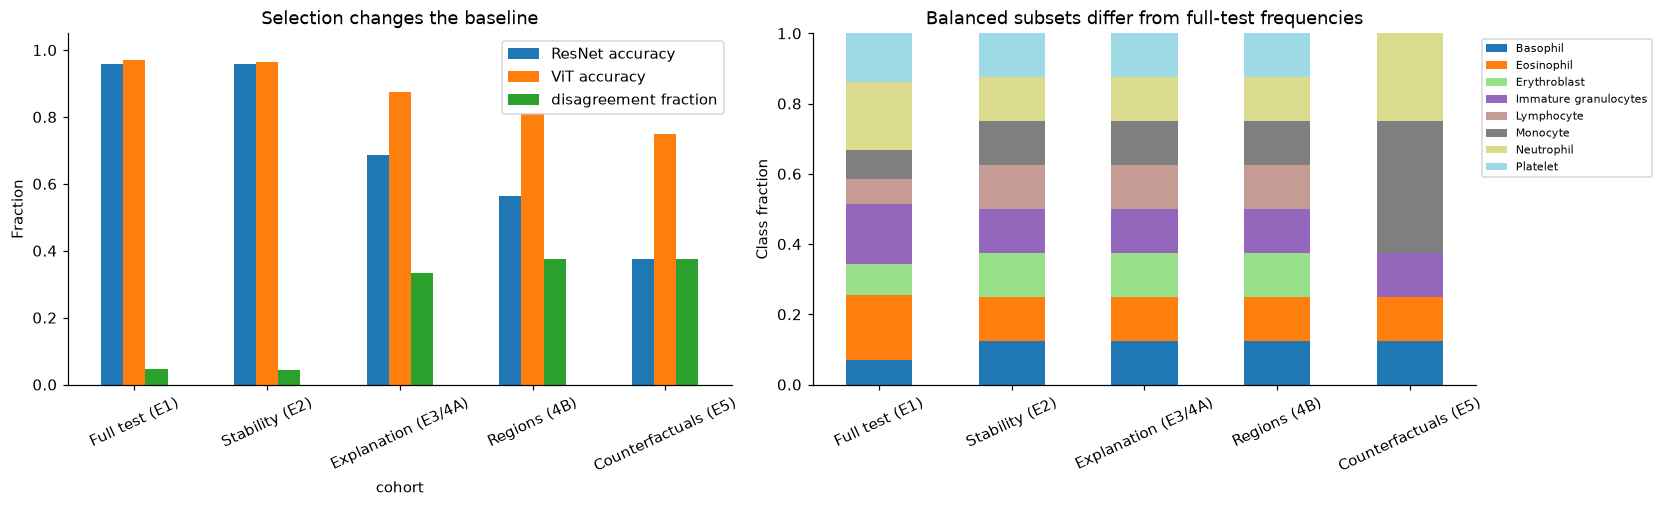

E2/E3 overlap: 9 images


In [2]:
manifest_2=read_json("results/stability/subset/manifest.json")
manifest_3=read_json("results/occlusion/subset/manifest.json")
manifest_4=read_json("results/color_background/subset/manifest.json")
manifest_5=read_json("results/counterfactual/subset/manifest.json")
cohorts={"Full test (E1)":all_test.index.to_numpy(),
         "Stability (E2)":np.array(manifest_2["sample_indices"]),
         "Explanation (E3/4A)":np.array(manifest_3["sample_indices"]),
         "Regions (4B)":np.array(manifest_4["region_sample_indices"]),
         "Counterfactuals (E5)":np.array(manifest_5["sample_indices"])}
np.testing.assert_array_equal(manifest_3["sample_indices"],manifest_4["sample_indices"])
for key in ("Regions (4B)","Counterfactuals (E5)"):
    assert set(cohorts[key])<=set(cohorts["Explanation (E3/4A)"])
rows=[]
for name,ids in cohorts.items():
    a=all_test.loc[ids]
    rows.append({"cohort":name,"n_images":len(a),
        "ResNet accuracy":(a.resnet_prediction==a.true_label).mean(),
        "ViT accuracy":(a.vit_prediction==a.true_label).mean(),
        "disagreement fraction":(~a.same_prediction).mean(),"both correct":(a.group=="both_correct").sum()})
cohort_table=pd.DataFrame(rows).set_index("cohort")
display(cohort_table)
fig,axes=plt.subplots(1,2,figsize=(15,4.5),layout="constrained")
cohort_table[["ResNet accuracy","ViT accuracy","disagreement fraction"]].plot.bar(ax=axes[0],rot=25)
axes[0].set(ylim=(0,1.05),title="Selection changes the baseline",ylabel="Fraction")
counts=pd.DataFrame({name:all_test.loc[ids].true_label.value_counts().reindex(range(8),fill_value=0)/len(ids)
                     for name,ids in cohorts.items()}).T
counts.columns=SHORT
counts.plot.bar(stacked=True,ax=axes[1],rot=25,colormap="tab20")
axes[1].set(ylabel="Class fraction",title="Balanced subsets differ from full-test frequencies")
axes[1].legend(fontsize=7,bbox_to_anchor=(1,1))
plt.show()
print("E2/E3 overlap:",len(set(cohorts["Stability (E2)"]) & set(cohorts["Explanation (E3/4A)"])),"images")

## 2. Dataset views and earlier exploratory plots

Examples, class means/variances and unsupervised pixel PCA are context, **not attribution**. PCA is fitted to test pixels for visualization only, not classification or performance estimation. A randomized solver avoids a costly full decomposition. No t-SNE or new model experiment is run.

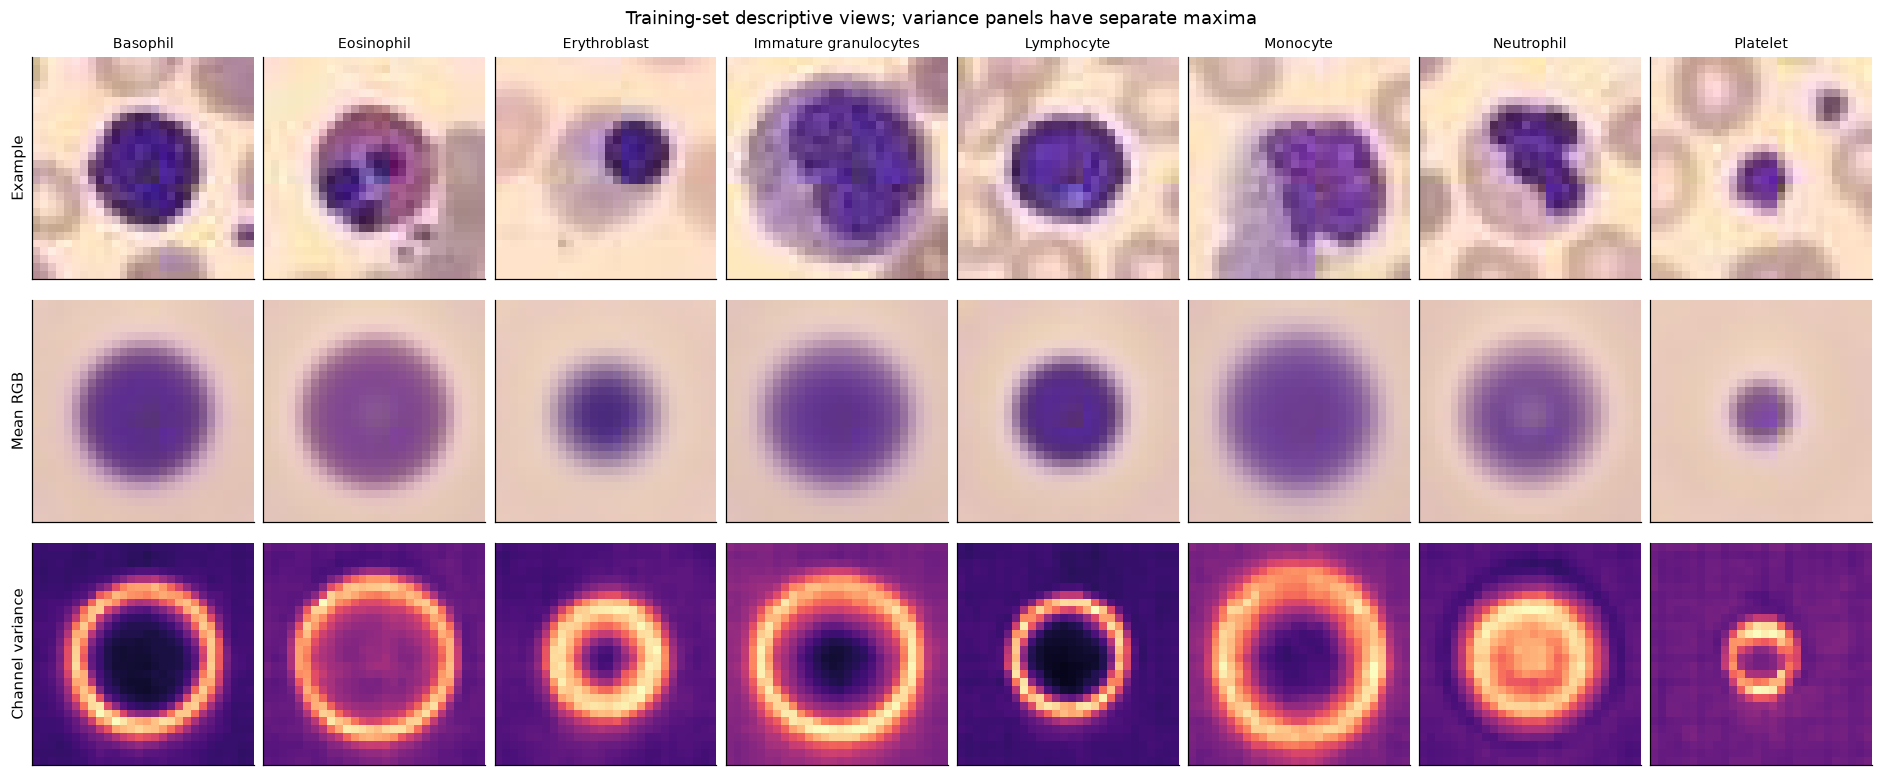

,train,val,test
Basophil,852,122,244
Eosinophil,2181,312,624
Erythroblast,1085,155,311
Immature granulocytes,2026,290,579
Lymphocyte,849,122,243
Monocyte,993,143,284
Neutrophil,2330,333,666
Platelet,1643,235,470


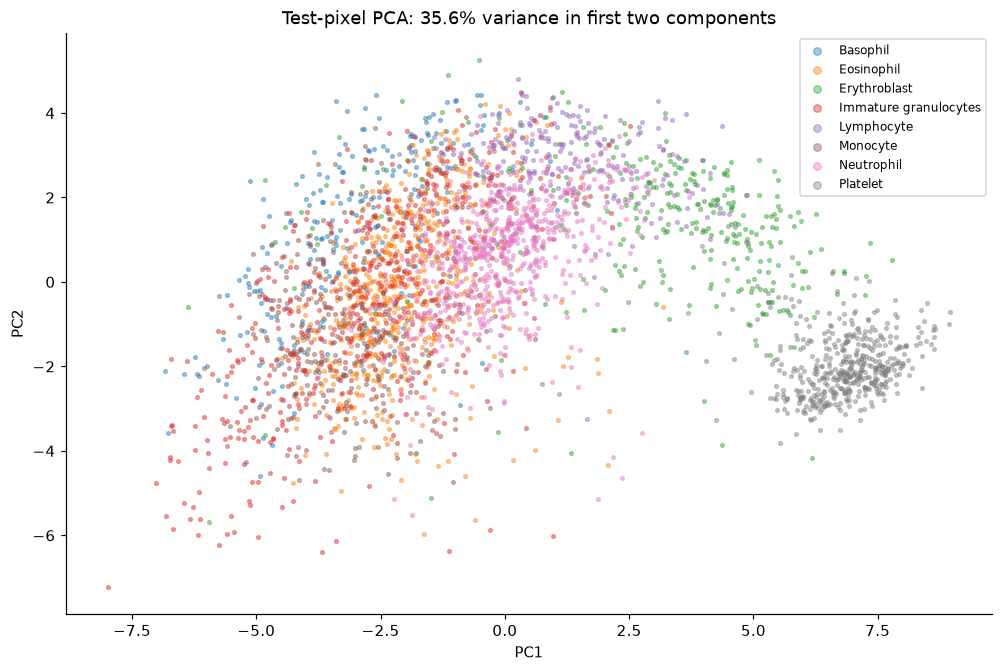

In [3]:
train_images,train_labels=dataset["train"]
test_images,test_labels=dataset["test"]
fig,axes=plt.subplots(3,8,figsize=(17,7),layout="constrained")
for cls in range(8):
    group=train_images[train_labels==cls]
    axes[0,cls].imshow(group[0]); axes[0,cls].set_title(SHORT[cls],fontsize=9)
    axes[1,cls].imshow(group.mean(0)/255)
    variance=group.astype(np.float32).var(0).mean(-1)
    axes[2,cls].imshow(variance,cmap="magma",vmin=0)
    for row in range(3): axes[row,cls].set_xticks([]); axes[row,cls].set_yticks([])
for ax,title in zip(axes[:,0],["Example","Mean RGB","Channel variance"]): ax.set_ylabel(title)
fig.suptitle("Training-set descriptive views; variance panels have separate maxima")
plt.show()
display(pd.DataFrame({s:np.bincount(labels,minlength=8) for s,(_,labels) in dataset.items()},index=SHORT))
x=test_images.reshape(len(test_images),-1).astype(np.float32)/255
pca=PCA(n_components=2,svd_solver="randomized",random_state=45)
projection=pca.fit_transform(x)
fig,ax=plt.subplots(figsize=(9,6),layout="constrained")
for cls in range(8):
    select=test_labels==cls
    ax.scatter(projection[select,0],projection[select,1],s=6,alpha=.4,label=SHORT[cls])
ax.set(title=f"Test-pixel PCA: {pca.explained_variance_ratio_.sum():.1%} variance in first two components",
       xlabel="PC1",ylabel="PC2")
ax.legend(fontsize=8,markerscale=2)
plt.show()
del x

## 3. Experiment 1: performance and paired disagreement

Accuracy alone hides complementary errors. A model-model disagreement matrix shows agreement, **not truth**: a shared wrong decision appears on its diagonal.

model,resnet,vit
split,,
train,1.0000,0.9948
val,0.9655,0.9778
test,0.9579,0.9699


,test images
group,
both_correct,3224
only_resnet_correct,53
only_vit_correct,94
both_incorrect,50


ViT minus ResNet test accuracy: 1.198 percentage points.
Paired decomposition: 94 ViT-only correct minus 53 ResNet-only correct.


C:\Users\Viktor\AppData\Local\Temp\ipykernel_20876\4242777993.py:17: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  im=ax.imshow(cm.div(cm.sum(1),axis=0),vmin=0,vmax=1,cmap="Blues")
C:\Users\Viktor\AppData\Local\Temp\ipykernel_20876\4242777993.py:17: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  im=ax.imshow(cm.div(cm.sum(1),axis=0),vmin=0,vmax=1,cmap="Blues")


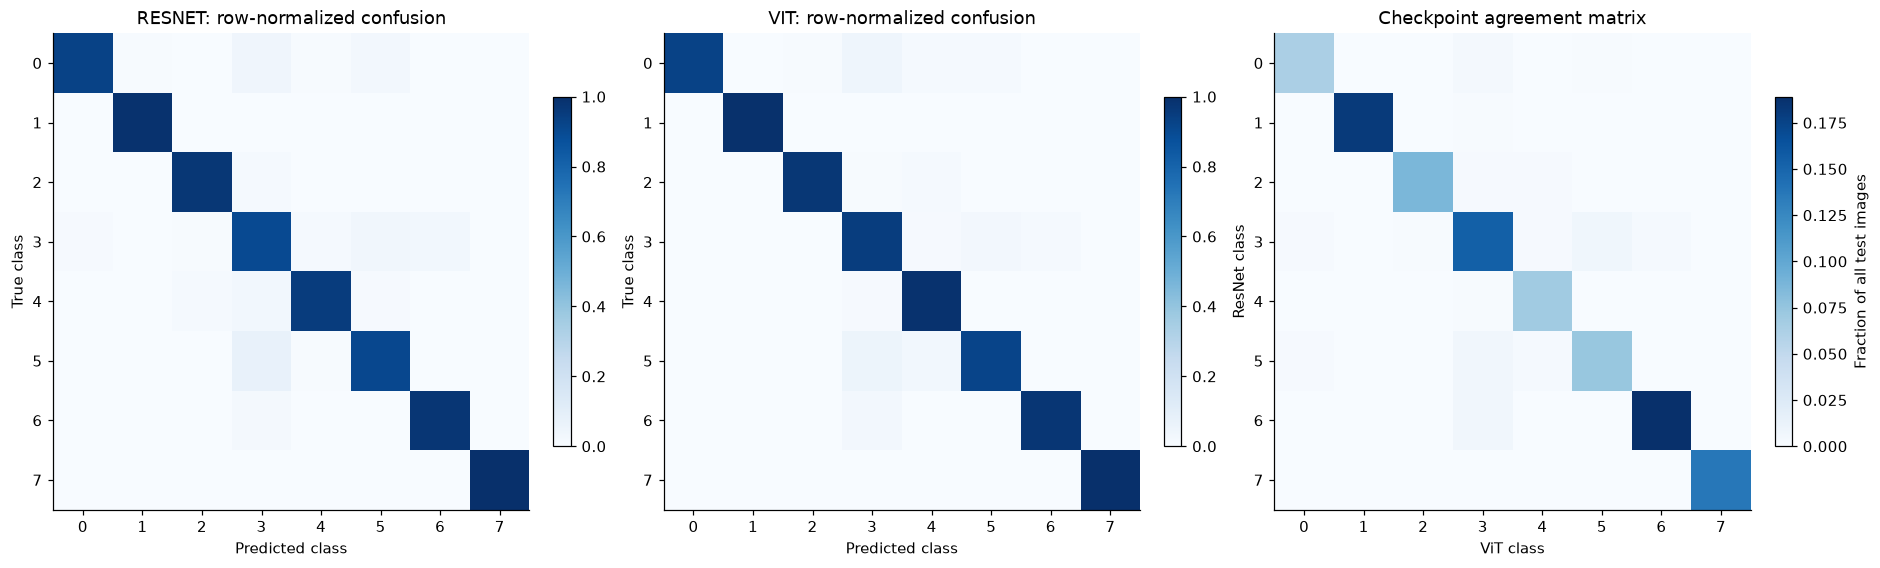

In [4]:
performance=[]
for split in dataset:
    a=analysis[split]
    for f in MODELS:
        performance.append({"split":split,"model":f,"n":len(a),
                            "accuracy":(a[f+"_prediction"]==a.true_label).mean()})
display(pd.DataFrame(performance).pivot(index="split",columns="model",values="accuracy").reindex(["train","val","test"]))
a=analysis["test"]
groups=a.group.value_counts().reindex(["both_correct","only_resnet_correct","only_vit_correct","both_incorrect"],fill_value=0)
display(groups.to_frame("test images"))
gap=((a.vit_prediction==a.true_label).mean()-(a.resnet_prediction==a.true_label).mean())*100
print(f"ViT minus ResNet test accuracy: {gap:.3f} percentage points.")
print(f"Paired decomposition: {groups.only_vit_correct} ViT-only correct minus {groups.only_resnet_correct} ResNet-only correct.")
fig,axes=plt.subplots(1,3,figsize=(17,5),layout="constrained")
for ax,f in zip(axes[:2],MODELS):
    cm=pd.crosstab(a.true_label,a[f+"_prediction"]).reindex(index=range(8),columns=range(8),fill_value=0)
    im=ax.imshow(cm.div(cm.sum(1),axis=0),vmin=0,vmax=1,cmap="Blues")
    ax.set(title=f"{f.upper()}: row-normalized confusion",xticks=range(8),yticks=range(8),xlabel="Predicted class",ylabel="True class")
    fig.colorbar(im,ax=ax,shrink=.7)
pairs=pd.crosstab(a.resnet_prediction,a.vit_prediction).reindex(index=range(8),columns=range(8),fill_value=0)
im=axes[2].imshow(pairs/len(a),cmap="Blues")
axes[2].set(title="Checkpoint agreement matrix",xticks=range(8),yticks=range(8),xlabel="ViT class",ylabel="ResNet class")
fig.colorbar(im,ax=axes[2],shrink=.7,label="Fraction of all test images")
plt.show()

### Confidence is not correctness

Reliability bins, NLL and multiclass Brier scores are descriptive diagnostics on this split. They do not establish calibrated or transferable uncertainty. Confident errors matter when interpreting p(original class) under interventions. No formal significance claims are made; donor/patient independence and ViT training provenance are not established here.

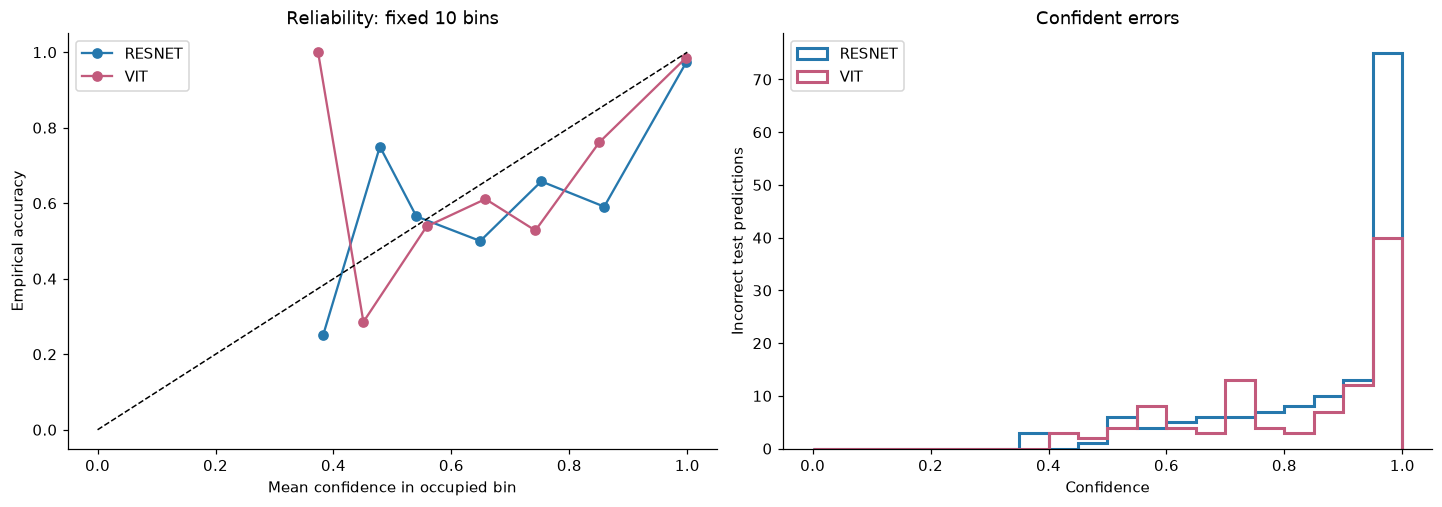

,NLL (clip 1e-12),multiclass Brier,10-bin ECE,wrong predictions,wrong with confidence >= 0.99,mean confidence on errors
model,,,,,,
resnet,0.2307,0.0735,0.0302,144,47,0.8735
vit,0.1123,0.0486,0.0167,103,20,0.8257


In [5]:
calibration_rows=[]
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
for f in MODELS:
    prob=pred["test"][f]["probabilities"].astype(np.float64)
    y=pred["test"][f]["labels"]
    confidence=prob.max(1); correct=prob.argmax(1)==y
    bins=np.minimum((confidence*10).astype(int),9)
    binned=pd.DataFrame({"bin":bins,"confidence":confidence,"correct":correct}).groupby("bin").agg(
        confidence=("confidence","mean"),accuracy=("correct","mean"),n=("correct","size"))
    ece=np.average(np.abs(binned.confidence-binned.accuracy),weights=binned.n)
    nll=-np.log(np.clip(prob[np.arange(len(y)),y],1e-12,1)).mean()
    brier=np.square(prob-np.eye(8)[y]).sum(1).mean()
    calibration_rows.append({"model":f,"NLL (clip 1e-12)":nll,"multiclass Brier":brier,"10-bin ECE":ece,
        "wrong predictions":int((~correct).sum()),"wrong with confidence >= 0.99":int(((confidence>=.99)&~correct).sum()),
        "mean confidence on errors":confidence[~correct].mean()})
    axes[0].plot(binned.confidence,binned.accuracy,"o-",color=COLORS[f],label=f.upper())
    axes[1].hist(confidence[~correct],bins=np.linspace(0,1,21),histtype="step",lw=2,color=COLORS[f],label=f.upper())
axes[0].plot([0,1],[0,1],"k--",lw=1)
axes[0].set(xlabel="Mean confidence in occupied bin",ylabel="Empirical accuracy",title="Reliability: fixed 10 bins")
axes[1].set(xlabel="Confidence",ylabel="Incorrect test predictions",title="Confident errors")
for ax in axes: ax.legend()
plt.show()
display(pd.DataFrame(calibration_rows).set_index("model"))

,sample_index,true_class,resnet_class,group,js_divergence_bits,resnet_confidence,vit_confidence
1182,1182,eosinophil,eosinophil,both_correct,0.3726,0.4972,0.5323
1516,1516,eosinophil,eosinophil,both_correct,0.3612,0.9993,0.4369
2384,2384,neutrophil,"immature granulocytes(myelocytes, metamyelocyt...",both_incorrect,0.3210,0.3800,0.9340
2972,2972,monocyte,monocyte,both_correct,0.3152,0.9998,0.4937
2223,2223,erythroblast,erythroblast,both_correct,0.3098,0.4996,0.9981
576,576,"immature granulocytes(myelocytes, metamyelocyt...",monocyte,both_incorrect,0.3057,0.5024,0.9988
963,963,"immature granulocytes(myelocytes, metamyelocyt...",lymphocyte,both_incorrect,0.3037,0.9988,0.5025
2869,2869,"immature granulocytes(myelocytes, metamyelocyt...","immature granulocytes(myelocytes, metamyelocyt...",both_correct,0.3011,0.5109,0.9964


Same-class test cases with JS >= 0.1 bits: 80
0.1 bits is an exploratory cutoff, not statistical significance.


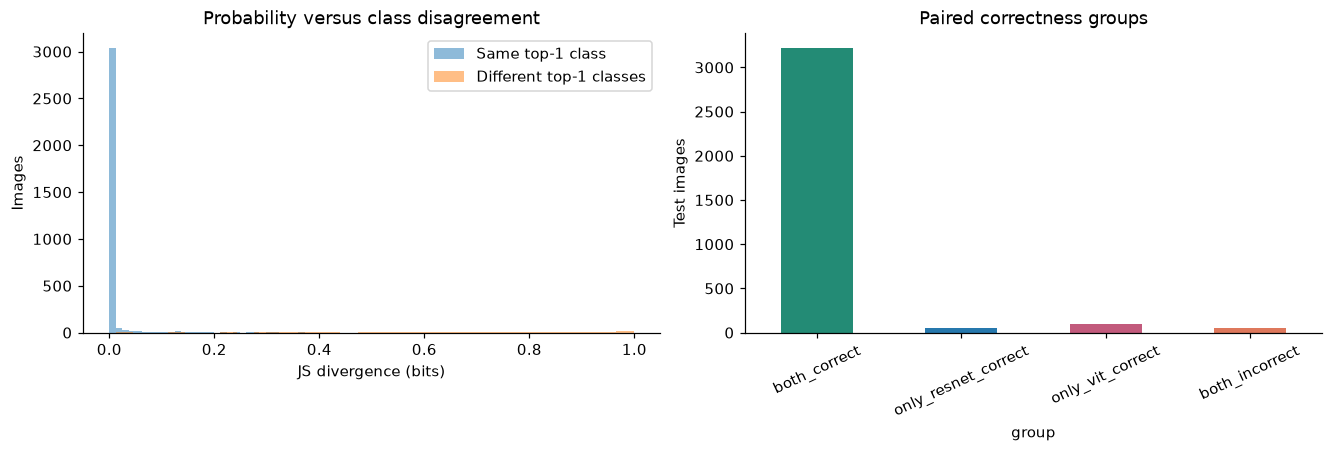

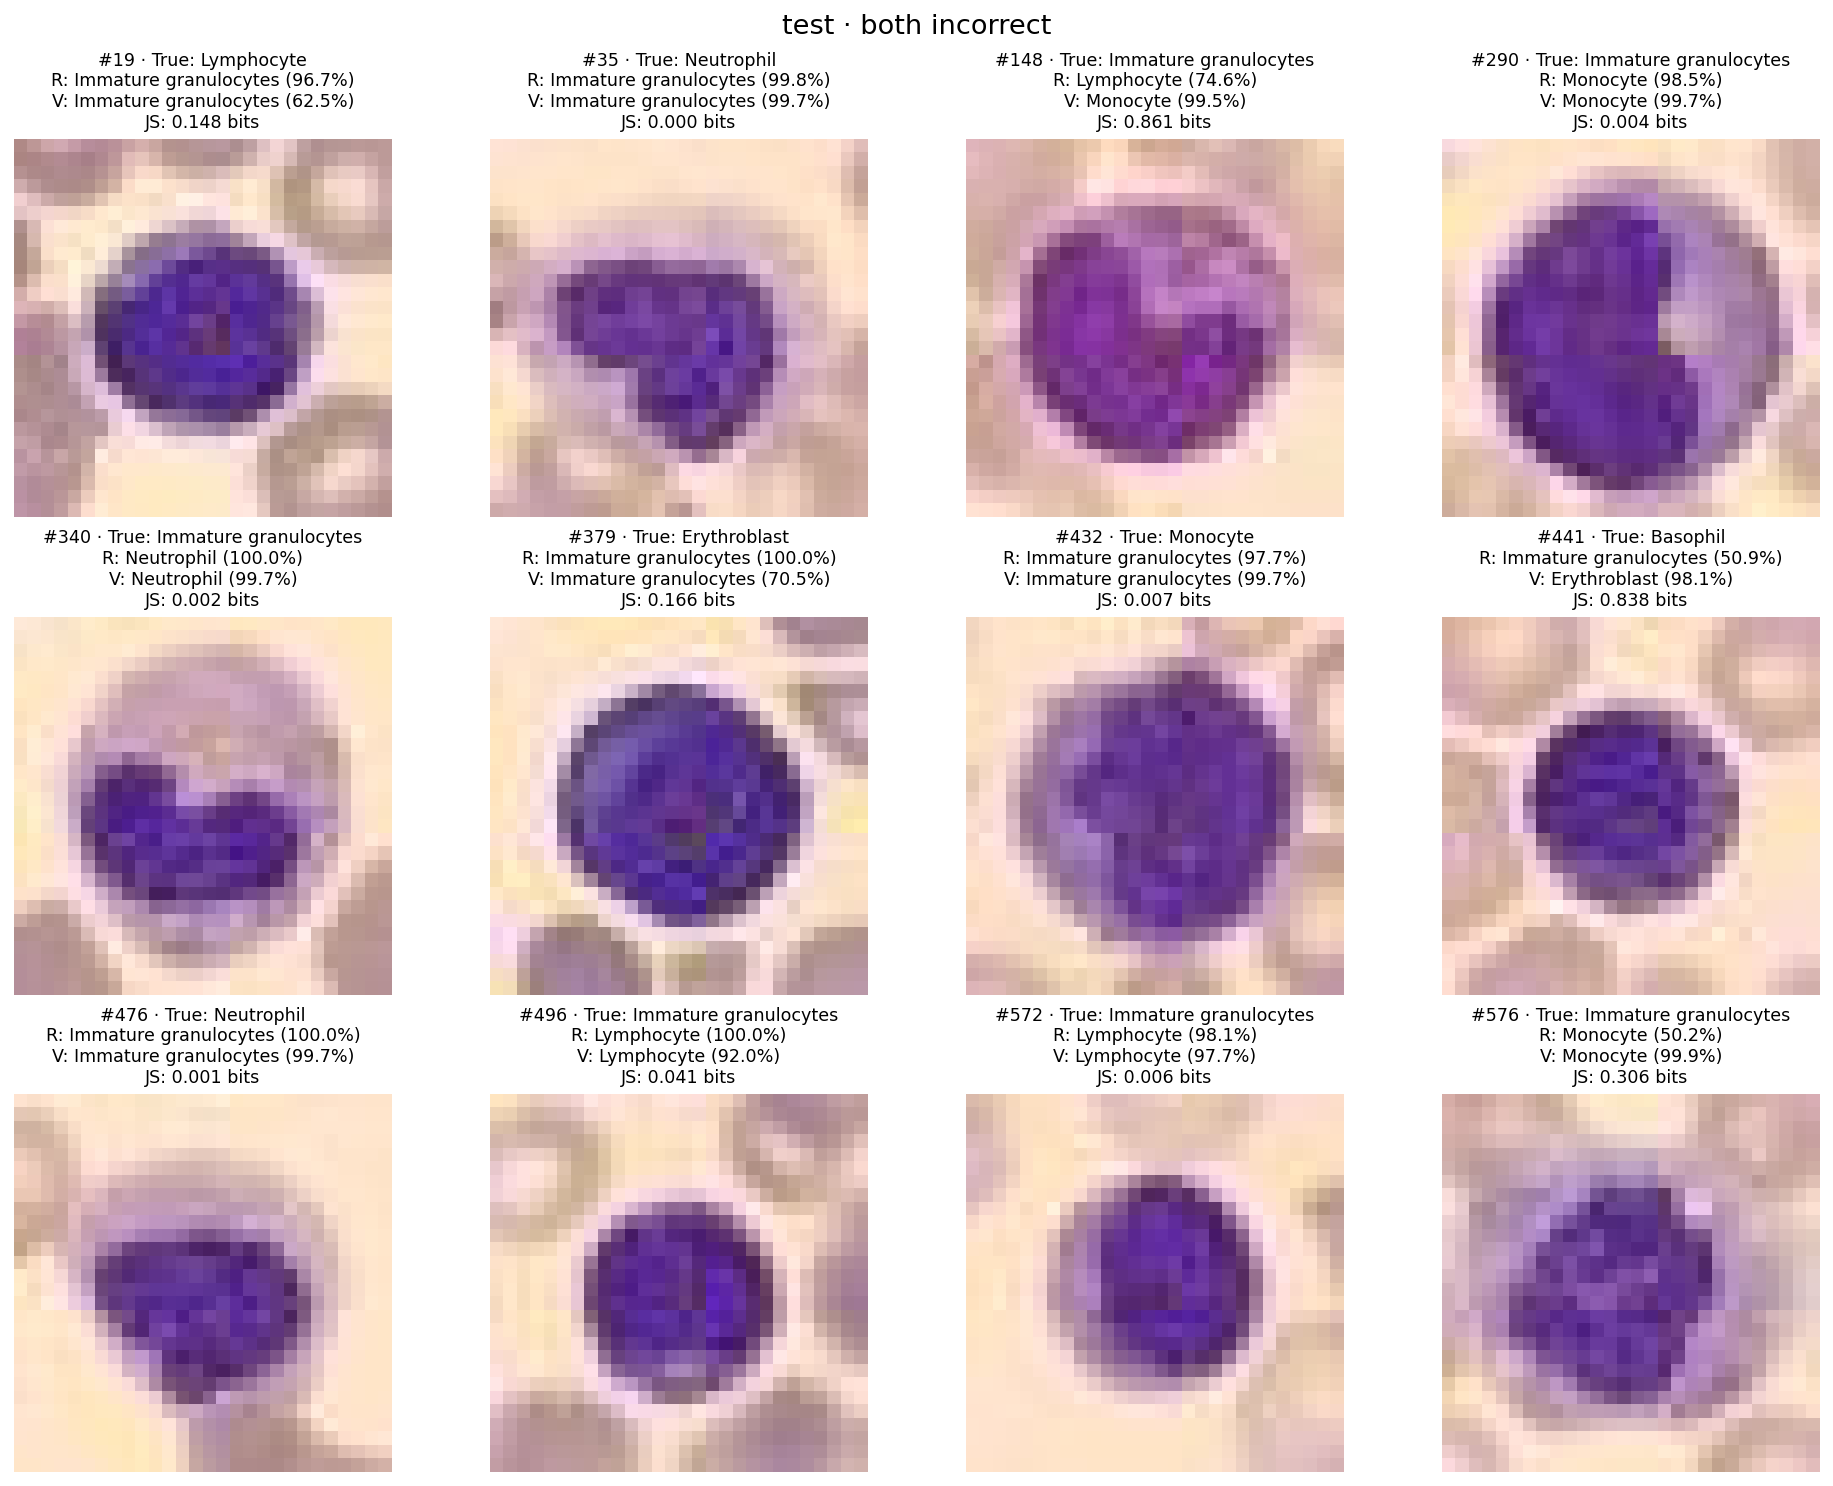

In [6]:
same=a[a.same_prediction]
display(same.nlargest(8,"js_divergence_bits")[["sample_index","true_class","resnet_class","group","js_divergence_bits",
                                             "resnet_confidence","vit_confidence"]])
print("Same-class test cases with JS >= 0.1 bits:",int((same.js_divergence_bits>=.1).sum()))
print("0.1 bits is an exploratory cutoff, not statistical significance.")
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
for is_same,label in ((True,"Same top-1 class"),(False,"Different top-1 classes")):
    axes[0].hist(a.loc[a.same_prediction==is_same,"js_divergence_bits"],bins=30,alpha=.5,label=label)
axes[0].set(xlabel="JS divergence (bits)",ylabel="Images",title="Probability versus class disagreement")
axes[0].legend()
groups.plot.bar(ax=axes[1],rot=25,color=["#238b75","#2678ad","#c25a7c","#de785c"])
axes[1].set(title="Paired correctness groups",ylabel="Test images")
plt.show()
saved_figure("results/analysis/test/figures/examples_both_incorrect.png")

### Earlier ResNet prediction exports: context, not new training

The `predictions/` directory contains exports for 12 supplied ResNet variants (architecture, input size, run). Recompute accuracy from their probabilities rather than trusting rounded filenames. These variants are **not** additional ViT-controlled experiments; different training/resolution settings prevent a causal architecture comparison.

**Schema check:** column 0 is a sample index, NOT the true label. Ground truth is joined by index from the correct dataset split; interpreting that column as truth would silently corrupt accuracy.

split,train,val,test
variant,,,
resnet18_224_1,1.0000,0.9720,0.9661
resnet18_224_2,1.0000,0.9696,0.9623
resnet18_28_2,1.0000,0.9609,0.9602
resnet18_224_3,1.0000,0.9626,0.9597
resnet18_28_1,1.0000,0.9655,0.9579
resnet50_28_2,1.0000,0.9638,0.9576
resnet50_28_1,1.0000,0.9609,0.9573
resnet18_28_3,1.0000,0.9667,0.9573
resnet50_224_3,1.0000,0.9667,0.9562


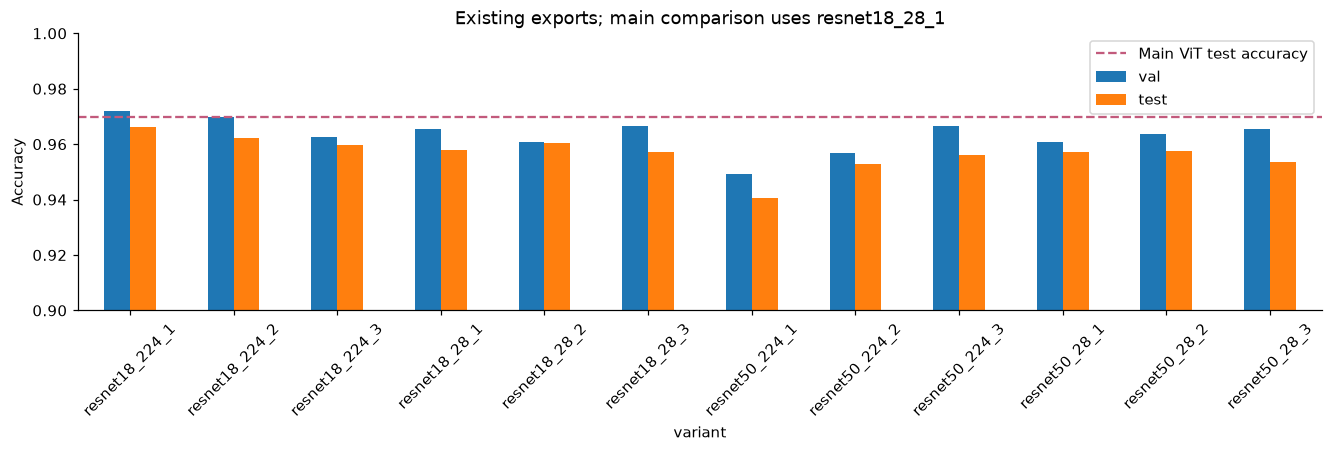

In [7]:
variant_rows=[]
for file in sorted((ROOT/"predictions").glob("*.csv")):
    split=file.name.split("_")[1]
    architecture,resolution,run=file.stem.split("@")[1].split("_")
    values=pd.read_csv(file,header=None).to_numpy()
    assert values.shape==(len(dataset[split][1]),9)
    ids=values[:,0].astype(np.int64)
    np.testing.assert_array_equal(ids,np.arange(len(dataset[split][1])))
    y=dataset[split][1][ids]
    np.testing.assert_allclose(values[:,1:].sum(1),1,atol=1e-5)
    variant_rows.append({"variant":file.stem.split("@")[1],"architecture":architecture,
                        "resolution":int(resolution),"run":int(run),"split":split,
                        "accuracy":(values[:,1:].argmax(1)==y).mean()})
variants=pd.DataFrame(variant_rows)
variant_table=variants.pivot(index="variant",columns="split",values="accuracy")
display(variant_table[["train","val","test"]].sort_values("test",ascending=False))
fig,ax=plt.subplots(figsize=(12,4),layout="constrained")
variant_table[["val","test"]].plot.bar(ax=ax,rot=45)
vit_accuracy=(all_test.vit_prediction==all_test.true_label).mean()
ax.axhline(vit_accuracy,color=COLORS["vit"],linestyle="--",label="Main ViT test accuracy")
ax.set(ylim=(.90,1),ylabel="Accuracy",title="Existing exports; main comparison uses resnet18_28_1")
ax.legend()
plt.show()

## 4. Experiment 2: stability, correctness and class-specific responses

Noise has three realizations per image. Average **within image/condition first**; do not count them as three independent images. Correct-label retention uses the shared initially-both-correct subset (301 images), whereas ordinary accuracy uses all 320.

The next cell reconstructs the exported aggregates to check those semantics. Curves show signed severity, own-baseline probability change, flip fraction and all-image accuracy. Grayscale is not part of E2.

Reconstructed aggregate flip fractions/accuracies match saved metrics.
Noise rows before/after within-image averaging: 7680 2560


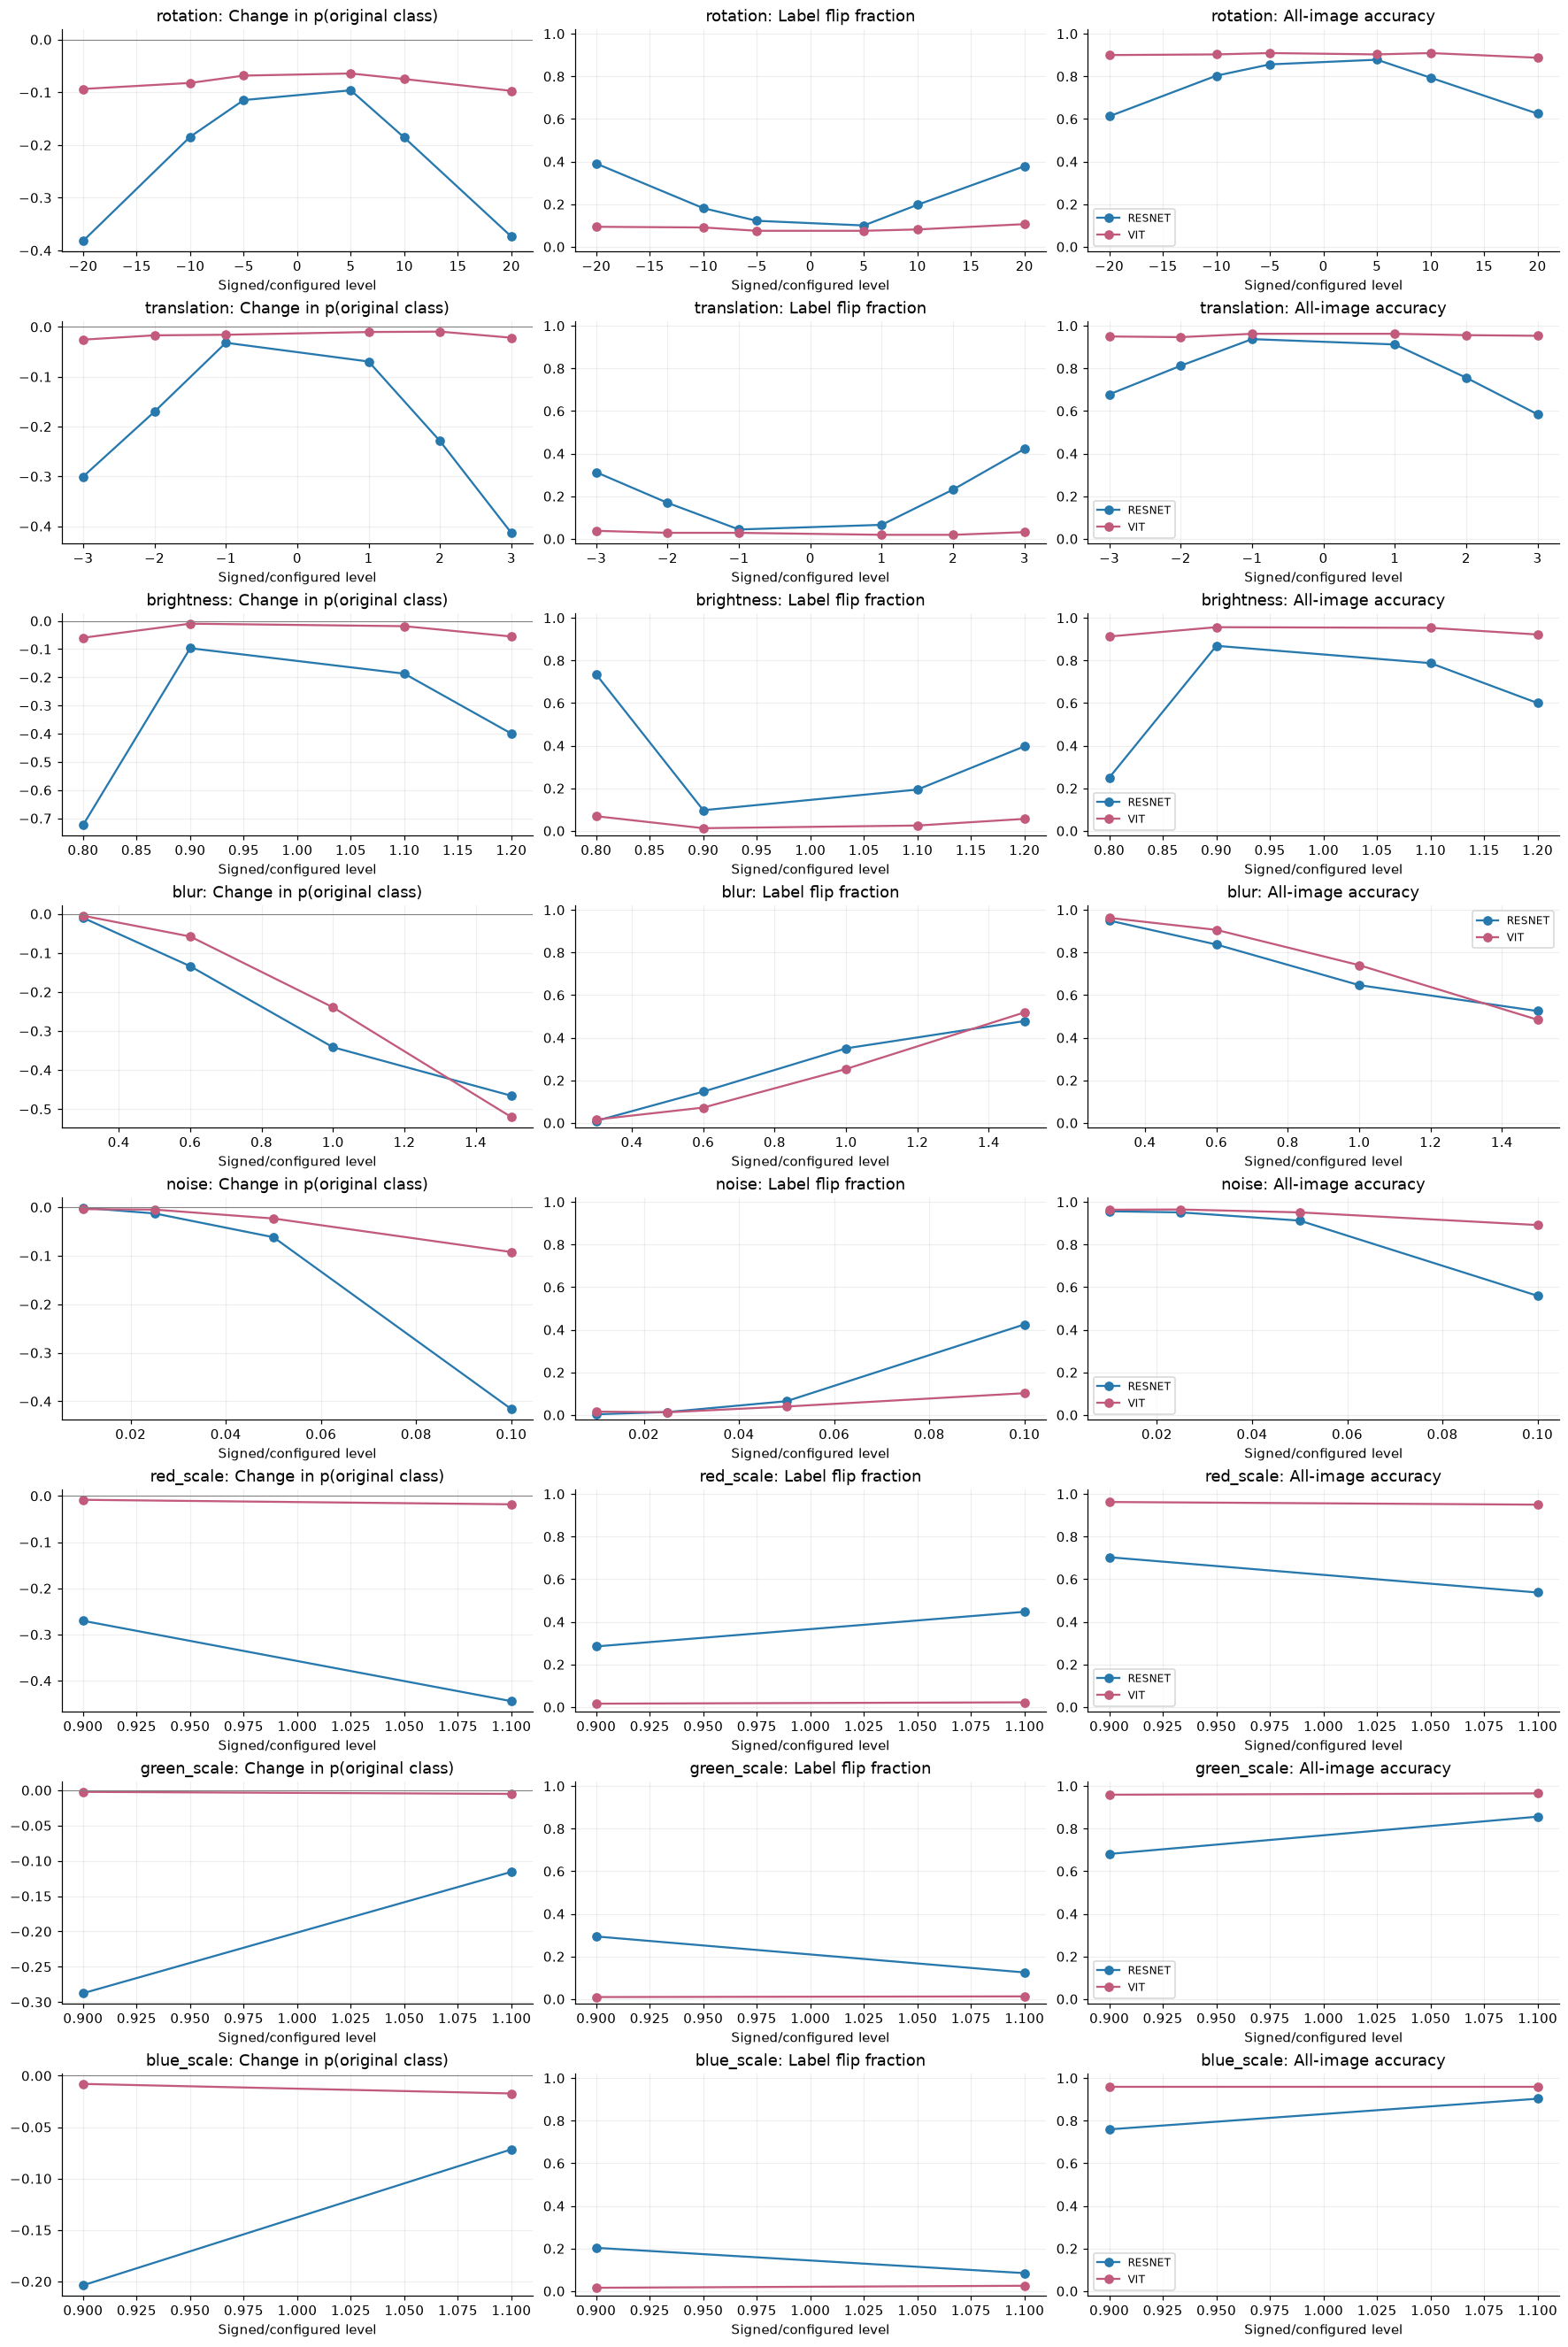

In [8]:
si=stability_images.copy()
si["baseline_correct"]=si.baseline_prediction==si.true_label
si["correct_to_wrong"]=si.baseline_correct & ~si.correct_after_transform
si["wrong_to_correct"]=~si.baseline_correct & si.correct_after_transform
per_image=si.groupby(["model","sample_index","transformation","level"],as_index=False).agg(
    flip=("label_flipped","mean"),accuracy=("correct_after_transform","mean"),
    retained=("retained_baseline_probability","mean"),
    correct_to_wrong=("correct_to_wrong","mean"),wrong_to_correct=("wrong_to_correct","mean"))
rebuilt=per_image.groupby(["model","transformation","level"]).agg(flip=("flip","mean"),accuracy=("accuracy","mean"))
exported=stability[stability.class_id==-1].set_index(["model","transformation","level"])
np.testing.assert_allclose(rebuilt.flip,exported.loc[rebuilt.index,"flip_fraction"],atol=1e-12)
np.testing.assert_allclose(rebuilt.accuracy,exported.loc[rebuilt.index,"accuracy"],atol=1e-12)
print("Reconstructed aggregate flip fractions/accuracies match saved metrics.")
print("Noise rows before/after within-image averaging:",len(si[si.transformation=="noise"]),len(per_image[per_image.transformation=="noise"]))
kinds=list(stability.transformation.drop_duplicates())
fig,axes=plt.subplots(len(kinds),3,figsize=(16,3*len(kinds)),layout="constrained")
for row,kind in enumerate(kinds):
    for f in MODELS:
        q=stability[(stability.class_id==-1)&(stability.transformation==kind)&(stability.model==f)].sort_values("level")
        for col,(metric,title) in enumerate((("probability_change","Change in p(original class)"),
                                             ("flip_fraction","Label flip fraction"),("accuracy","All-image accuracy"))):
            axes[row,col].plot(q.level,q[metric],"o-",color=COLORS[f],label=f.upper())
            axes[row,col].set(title=f"{kind}: {title}",xlabel="Signed/configured level")
            axes[row,col].grid(alpha=.2)
    axes[row,0].axhline(0,color="gray",lw=.7)
    for ax in axes[row,1:]: ax.set_ylim(-.02,1.02)
    axes[row,2].legend(fontsize=8)
plt.show()

correct_to_wrong  wrong_to_correct  \
model  transformation level                                       
resnet brightness      0.8              228.0               1.0   
vit    blur            1.5              157.0               3.0   
resnet blur            1.5              143.0               4.0   
       red_scale       1.1              137.0               2.0   
       noise           0.1              128.0               0.0   
       translation     3.0              126.0               6.0   
       brightness      1.2              120.0               5.0   
       rotation       -20.0             117.0               6.0   
                       20.0             113.0               6.0   
       blur            1.0              105.0               5.0   
       translation    -3.0               94.0               4.0   
       green_scale     0.9               89.0               0.0   

                             net_correctness_loss  
model  transformation level                        
resnet brightness      0.8                  227.0  
vit    blur            1.5                  154.0  
resnet blur            1.5                  139.0  
       red_scale       1.1                  135.0  
       noise           0.1                  128.0  
       translation     3.0                  120.0  
       brightness      1.2                  115.0  
       rotation       -20.0                 111.0  
                       20.0                 107.0  
       blur            1.0                  100.0  
       translation    -3.0                   90.0  
       green_scale     0.9                   89.0

Counts are mean counts across noise realizations where applicable, not extra independent images.


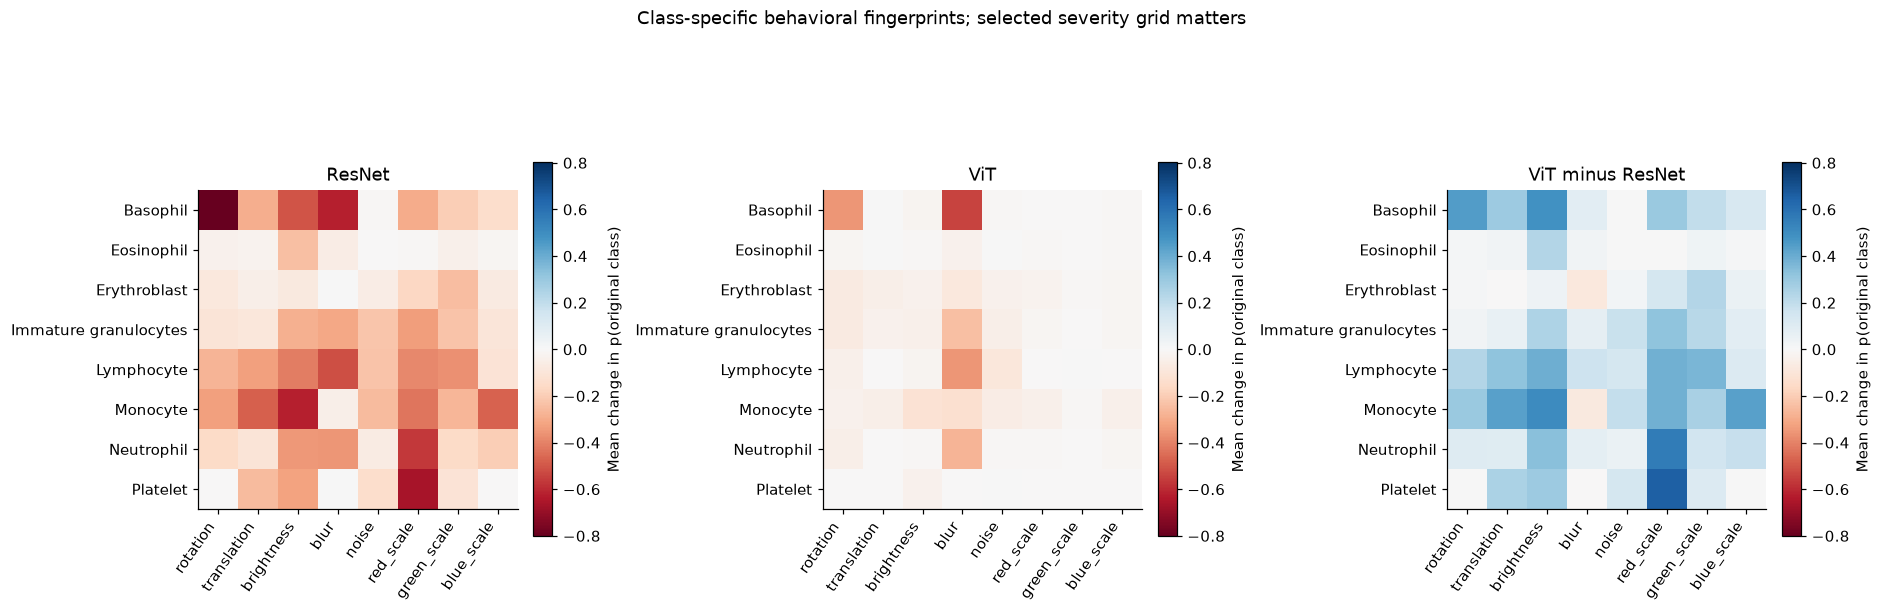

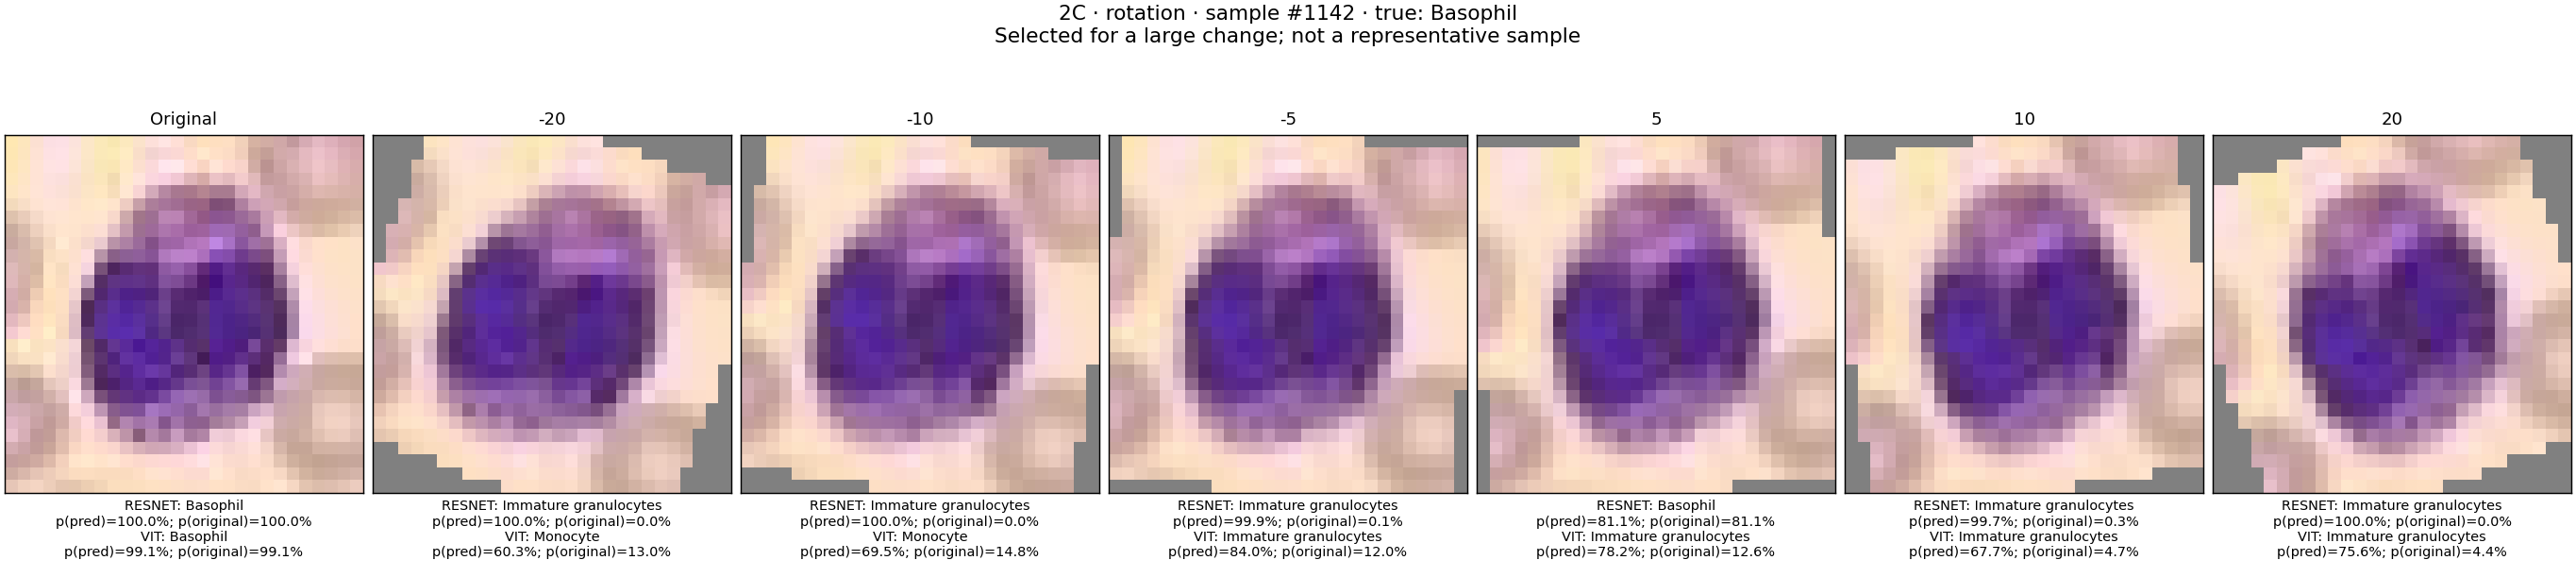

In [9]:
tradeoffs=per_image.groupby(["model","transformation","level"])[["correct_to_wrong","wrong_to_correct"]].sum()
tradeoffs["net_correctness_loss"]=tradeoffs.correct_to_wrong-tradeoffs.wrong_to_correct
display(tradeoffs.sort_values("net_correctness_loss",ascending=False).head(12))
print("Counts are mean counts across noise realizations where applicable, not extra independent images.")
matrices={f:fingerprints[fingerprints.model==f].pivot(index="true_class",columns="transformation",values="mean_probability_change").reindex(index=range(8),columns=kinds)
          for f in MODELS}
scale=max(float(np.abs(m.to_numpy()).max()) for m in matrices.values())
fig,axes=plt.subplots(1,3,figsize=(17,6),layout="constrained")
for ax,m,title in zip(axes,[matrices["resnet"],matrices["vit"],matrices["vit"]-matrices["resnet"]],
                      ["ResNet","ViT","ViT minus ResNet"]):
    im=ax.imshow(m,cmap="RdBu",vmin=-scale,vmax=scale)
    ax.set(title=title,xticks=range(len(kinds)),xticklabels=kinds,yticks=range(8),yticklabels=SHORT)
    plt.setp(ax.get_xticklabels(),rotation=55,ha="right")
    fig.colorbar(im,ax=ax,shrink=.6,label="Mean change in p(original class)")
fig.suptitle("Class-specific behavioral fingerprints; selected severity grid matters")
plt.show()
# One representative of the saved transition-grid family; every saved image is linked in the atlas.
transition_figures=sorted((RESULTS/"stability/figures/transition_grids").glob("rotation*.png"))
if transition_figures: saved_figure(transition_figures[0].relative_to(ROOT))

## 5. Experiment 3: spatial occlusion sensitivity

Use the **same target class across models**. The true class is available for all images; preferred-class maps can refer to different decisions and should not be compared as if identical targets.

Each map is a **13x13 grid of overlapping 4x4 patch positions**, not a 28x28 pixel attribution. Importance is original p(target) minus occluded p(target): red means the patch change reduced the target score. No biological segmentation, attention or causal anatomical attribution is established.

model         resnet                       vit              
                mean      median count    mean  median count
both_correct                                                
False         0.0591  3.9950e-02    18  0.0629  0.0395    18
True          0.0090  1.9010e-07    30  0.0069  0.0001    30

,mean,median,count
both_correct,,,
False,0.2493,0.2447,18
True,0.1131,0.0855,26


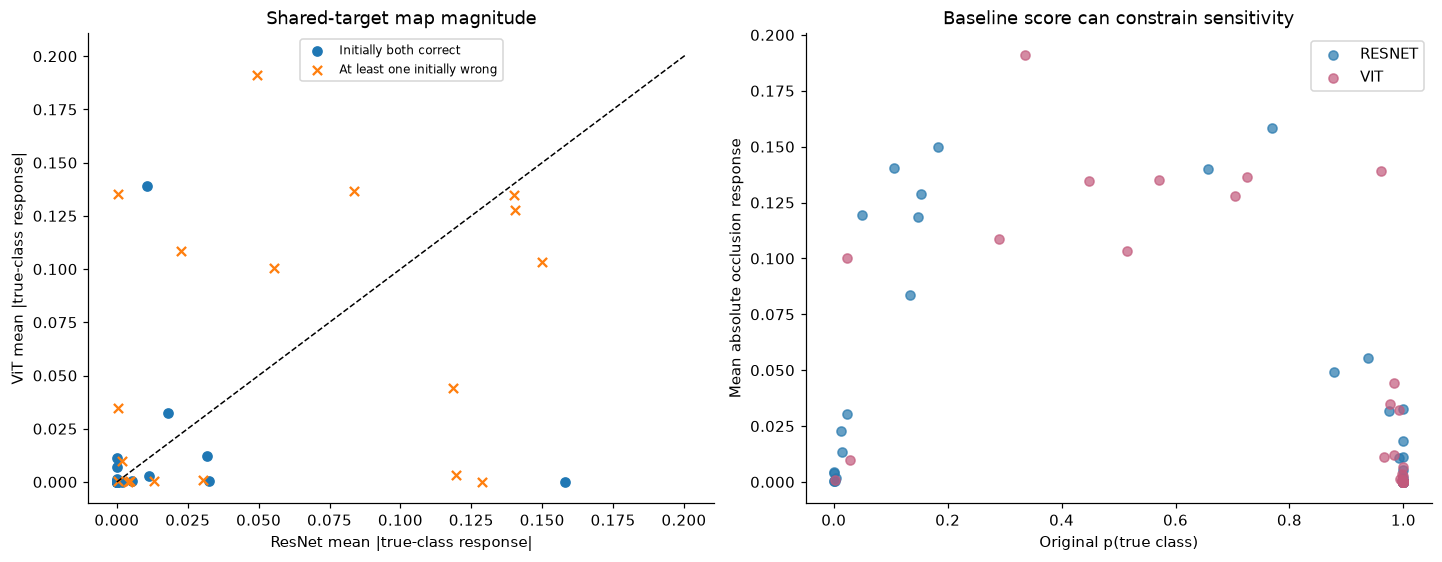

Spatial rank correlations are descriptive; overlapping map positions are not independent tests.


In [10]:
occlusion_true=occlusion[occlusion.target_type=="true_class"].copy()
response=occlusion_true.pivot(index="sample_index",columns="model",values="mean_absolute_importance")
response["both_correct"]=all_test.loc[response.index,"group"]=="both_correct"
response["true_label"]=all_test.loc[response.index,"true_label"]
response["absolute_model_gap"]=(response.resnet-response.vit).abs()
map_arrays={}; correlations=[]
for index in response.index:
    with np.load(RESULTS/f"occlusion/maps/sample_{index:05d}.npz",allow_pickle=False) as z:
        maps={f:z[f"true_class_{f}"] for f in MODELS}
    map_arrays[int(index)]=maps
    for f in MODELS:
        np.testing.assert_allclose(np.abs(maps[f]).mean(),response.loc[index,f],rtol=1e-5,atol=1e-8)
    r,v=maps["resnet"].ravel(),maps["vit"].ravel()
    rho=float(spearmanr(r,v).statistic) if r.std()>0 and v.std()>0 else np.nan
    correlations.append({"sample_index":index,"spatial_rank_correlation":rho,
                         "both_correct":response.loc[index,"both_correct"]})
spatial_correlations=pd.DataFrame(correlations).set_index("sample_index")
display(response.groupby("both_correct")[["resnet","vit"]].agg(["mean","median","count"]))
display(spatial_correlations.groupby("both_correct").spatial_rank_correlation.agg(["mean","median","count"]))
fig,axes=plt.subplots(1,2,figsize=(13,5),layout="constrained")
for state,marker in ((True,"o"),(False,"x")):
    select=response.both_correct==state
    axes[0].scatter(response.loc[select,"resnet"],response.loc[select,"vit"],marker=marker,
                    label="Initially both correct" if state else "At least one initially wrong")
limit=response[list(MODELS)].to_numpy().max()*1.05
axes[0].plot([0,limit],[0,limit],"k--",lw=1)
axes[0].set(xlabel="ResNet mean |true-class response|",ylabel="ViT mean |true-class response|",title="Shared-target map magnitude")
axes[0].legend(fontsize=8)
for f in MODELS:
    q=occlusion_true[occlusion_true.model==f]
    axes[1].scatter(q.baseline_target_probability,q.mean_absolute_importance,label=f.upper(),alpha=.7,color=COLORS[f])
axes[1].set(xlabel="Original p(true class)",ylabel="Mean absolute occlusion response",title="Baseline score can constrain sensitivity")
axes[1].legend()
plt.show()
print("Spatial rank correlations are descriptive; overlapping map positions are not independent tests.")

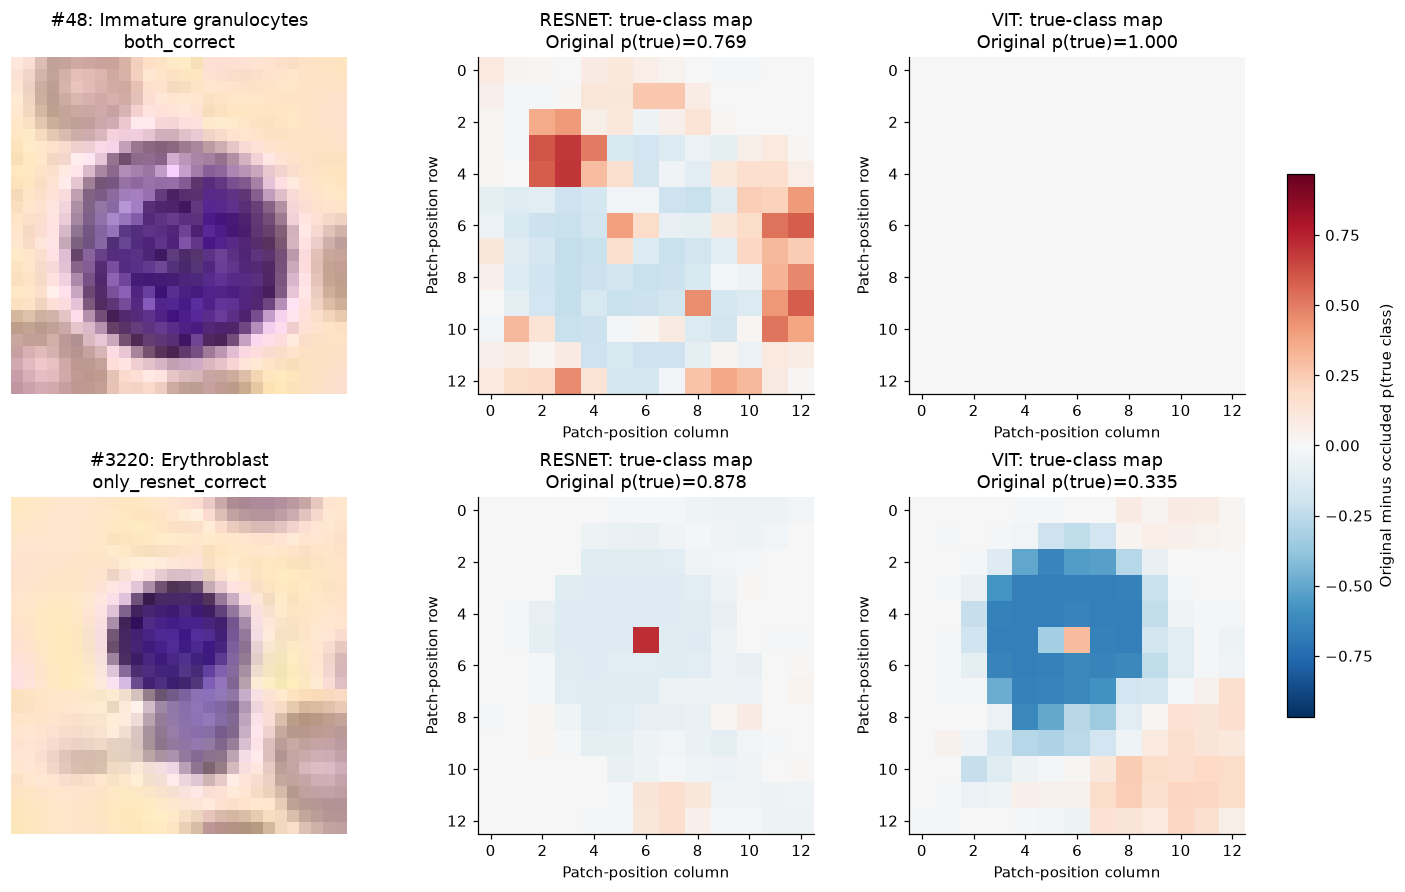

In [11]:
# Post-hoc illustrations, explicitly contrasting initial correctness.
chosen=[]
for both_correct in (True,False):
    pool=response[response.both_correct==both_correct]
    if len(pool): chosen.append(int(pool.absolute_model_gap.idxmax()))
vmax=max(abs(x) for x in read_json("results/occlusion/summary.json")["global_color_scale"])
fig,axes=plt.subplots(len(chosen),3,figsize=(13,4*len(chosen)),squeeze=False,layout="constrained")
for row,index in enumerate(chosen):
    cls=int(all_test.loc[index,"true_label"])
    axes[row,0].imshow(test_images[index]); axes[row,0].axis("off")
    axes[row,0].set_title(f"#{index}: {SHORT[cls]}\n{all_test.loc[index,'group']}")
    for col,f in enumerate(MODELS,1):
        matrix=map_arrays[index][f]
        im=axes[row,col].imshow(matrix,cmap="RdBu_r",vmin=-vmax,vmax=vmax)
        b=occlusion_true[(occlusion_true.sample_index==index)&(occlusion_true.model==f)].iloc[0]
        axes[row,col].set_title(f"{f.upper()}: true-class map\nOriginal p(true)={b.baseline_target_probability:.3f}")
        axes[row,col].set(xlabel="Patch-position column",ylabel="Patch-position row")
fig.colorbar(im,ax=axes[:,1:].ravel().tolist(),shrink=.7,label="Original minus occluded p(true class)")
plt.show()

## 6. Experiment 4A: color sensitivity, with correctness controlled

Grayscale and saturation 0.5/1.5 are **feature ablations/stress tests**. Other levels are operationally mild RGB changes, not validated microscope/stain simulations or guaranteed label-preserving transformations.

Compare both the entire 48-image set and the **same initially-both-correct images**. This separates part of the baseline-correctness imbalance from sensitivity. Repeated conditions on one image remain correlated observations.

flips          n     accuracy        
model           resnet vit resnet vit   resnet     vit
transformation                                        
original             0   0     48  48   0.6875  0.8750
grayscale           43  22     48  48   0.1250  0.5417
saturation_0.5      37   7     48  48   0.2500  0.8125
saturation_0.8      16   4     48  48   0.6458  0.8542
saturation_1.2      10   2     48  48   0.6875  0.8333
saturation_1.5      25   6     48  48   0.4375  0.8125
red_scale_0.95       8   2     48  48   0.6458  0.8333
red_scale_1.05      15   4     48  48   0.6458  0.9375
blue_scale_0.95      8   3     48  48   0.7083  0.9167
blue_scale_1.05      2   3     48  48   0.6875  0.8125
brightness_0.9      13   1     48  48   0.6458  0.8958
brightness_0.95     11   0     48  48   0.6458  0.8750
brightness_1.05      7   2     48  48   0.6042  0.8750
brightness_1.1      11   2     48  48   0.5833  0.8750

,subset,model,unique_images,image-condition pairs,flips,flip_fraction,correct_to_wrong,wrong_to_correct
0,All 48,resnet,48,480,101,0.2104,48,30
1,All 48,vit,48,480,23,0.0479,11,9
2,Initially both correct,resnet,30,300,35,0.1167,35,0
3,Initially both correct,vit,30,300,0,0.0000,0,0


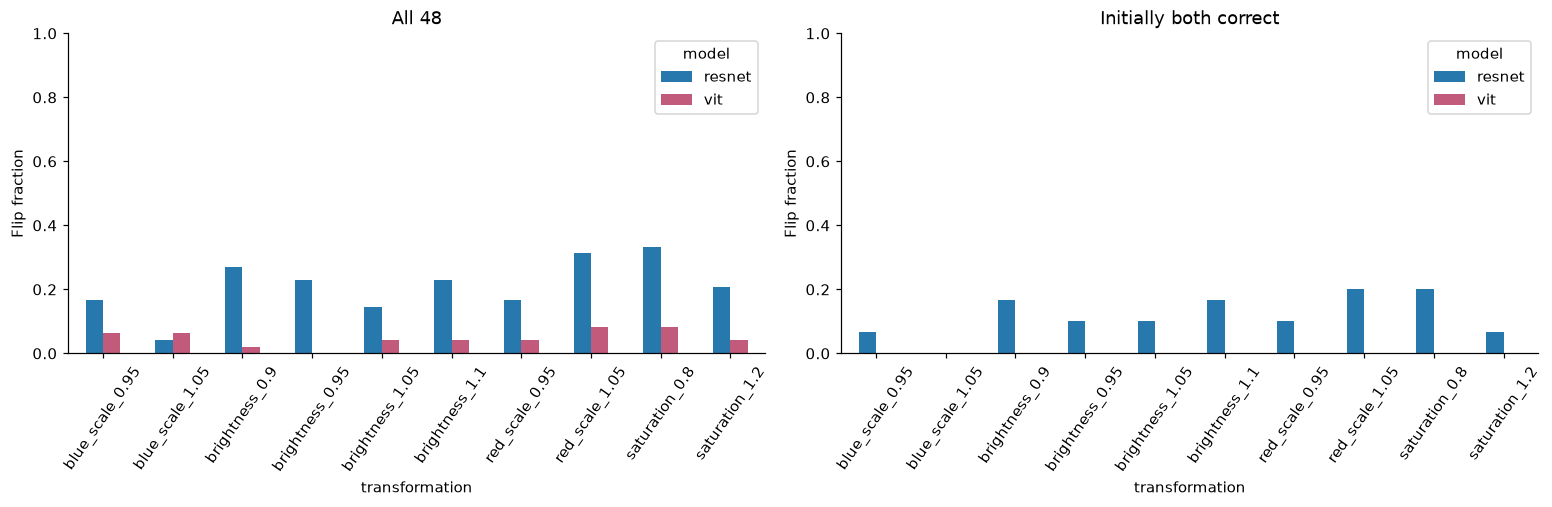

Conditioned comparison: interpret fractions using unique-image denominators, not independent trials.


In [12]:
color["baseline_correct"]=color.baseline_prediction==color.true_label
color["both_correct"]=color.sample_index.map((all_test.group=="both_correct").to_dict())
color["correct_to_wrong"]=color.baseline_correct & ~color.correct
color["wrong_to_correct"]=~color.baseline_correct & color.correct
mild=color[color.mild].copy()
condition_order=[x["key"] for x in read_json("results/color_background/config.json")["color_conditions"]]
color_stats=color.groupby(["model","transformation"]).agg(n=("sample_index","size"),
    flips=("label_flipped","sum"),flip_fraction=("label_flipped","mean"),
    accuracy=("correct","mean"),mean_true_class_delta=("true_class_probability_change","mean"))
display(color_stats[["flips","n","accuracy"]].unstack("model").reindex(condition_order))
comparisons=[]
for group,mask in (("All 48",np.ones(len(mild),bool)),("Initially both correct",mild.both_correct.to_numpy())):
    for f in MODELS:
        q=mild[mask & (mild.model.to_numpy()==f)]
        comparisons.append({"subset":group,"model":f,"unique_images":q.sample_index.nunique(),
            "image-condition pairs":len(q),"flips":q.label_flipped.sum(),"flip_fraction":q.label_flipped.mean(),
            "correct_to_wrong":q.correct_to_wrong.sum(),"wrong_to_correct":q.wrong_to_correct.sum()})
color_controlled=pd.DataFrame(comparisons)
display(color_controlled)
fig,axes=plt.subplots(1,2,figsize=(14,4.5),layout="constrained")
for col,subset in enumerate(("All 48","Initially both correct")):
    q=mild if col==0 else mild[mild.both_correct]
    q.groupby(["transformation","model"]).label_flipped.mean().unstack().plot.bar(ax=axes[col],rot=55,color=[COLORS[f] for f in MODELS])
    axes[col].set(title=subset,ylabel="Flip fraction",ylim=(0,1))
plt.show()
print("Conditioned comparison: interpret fractions using unique-image denominators, not independent trials.")

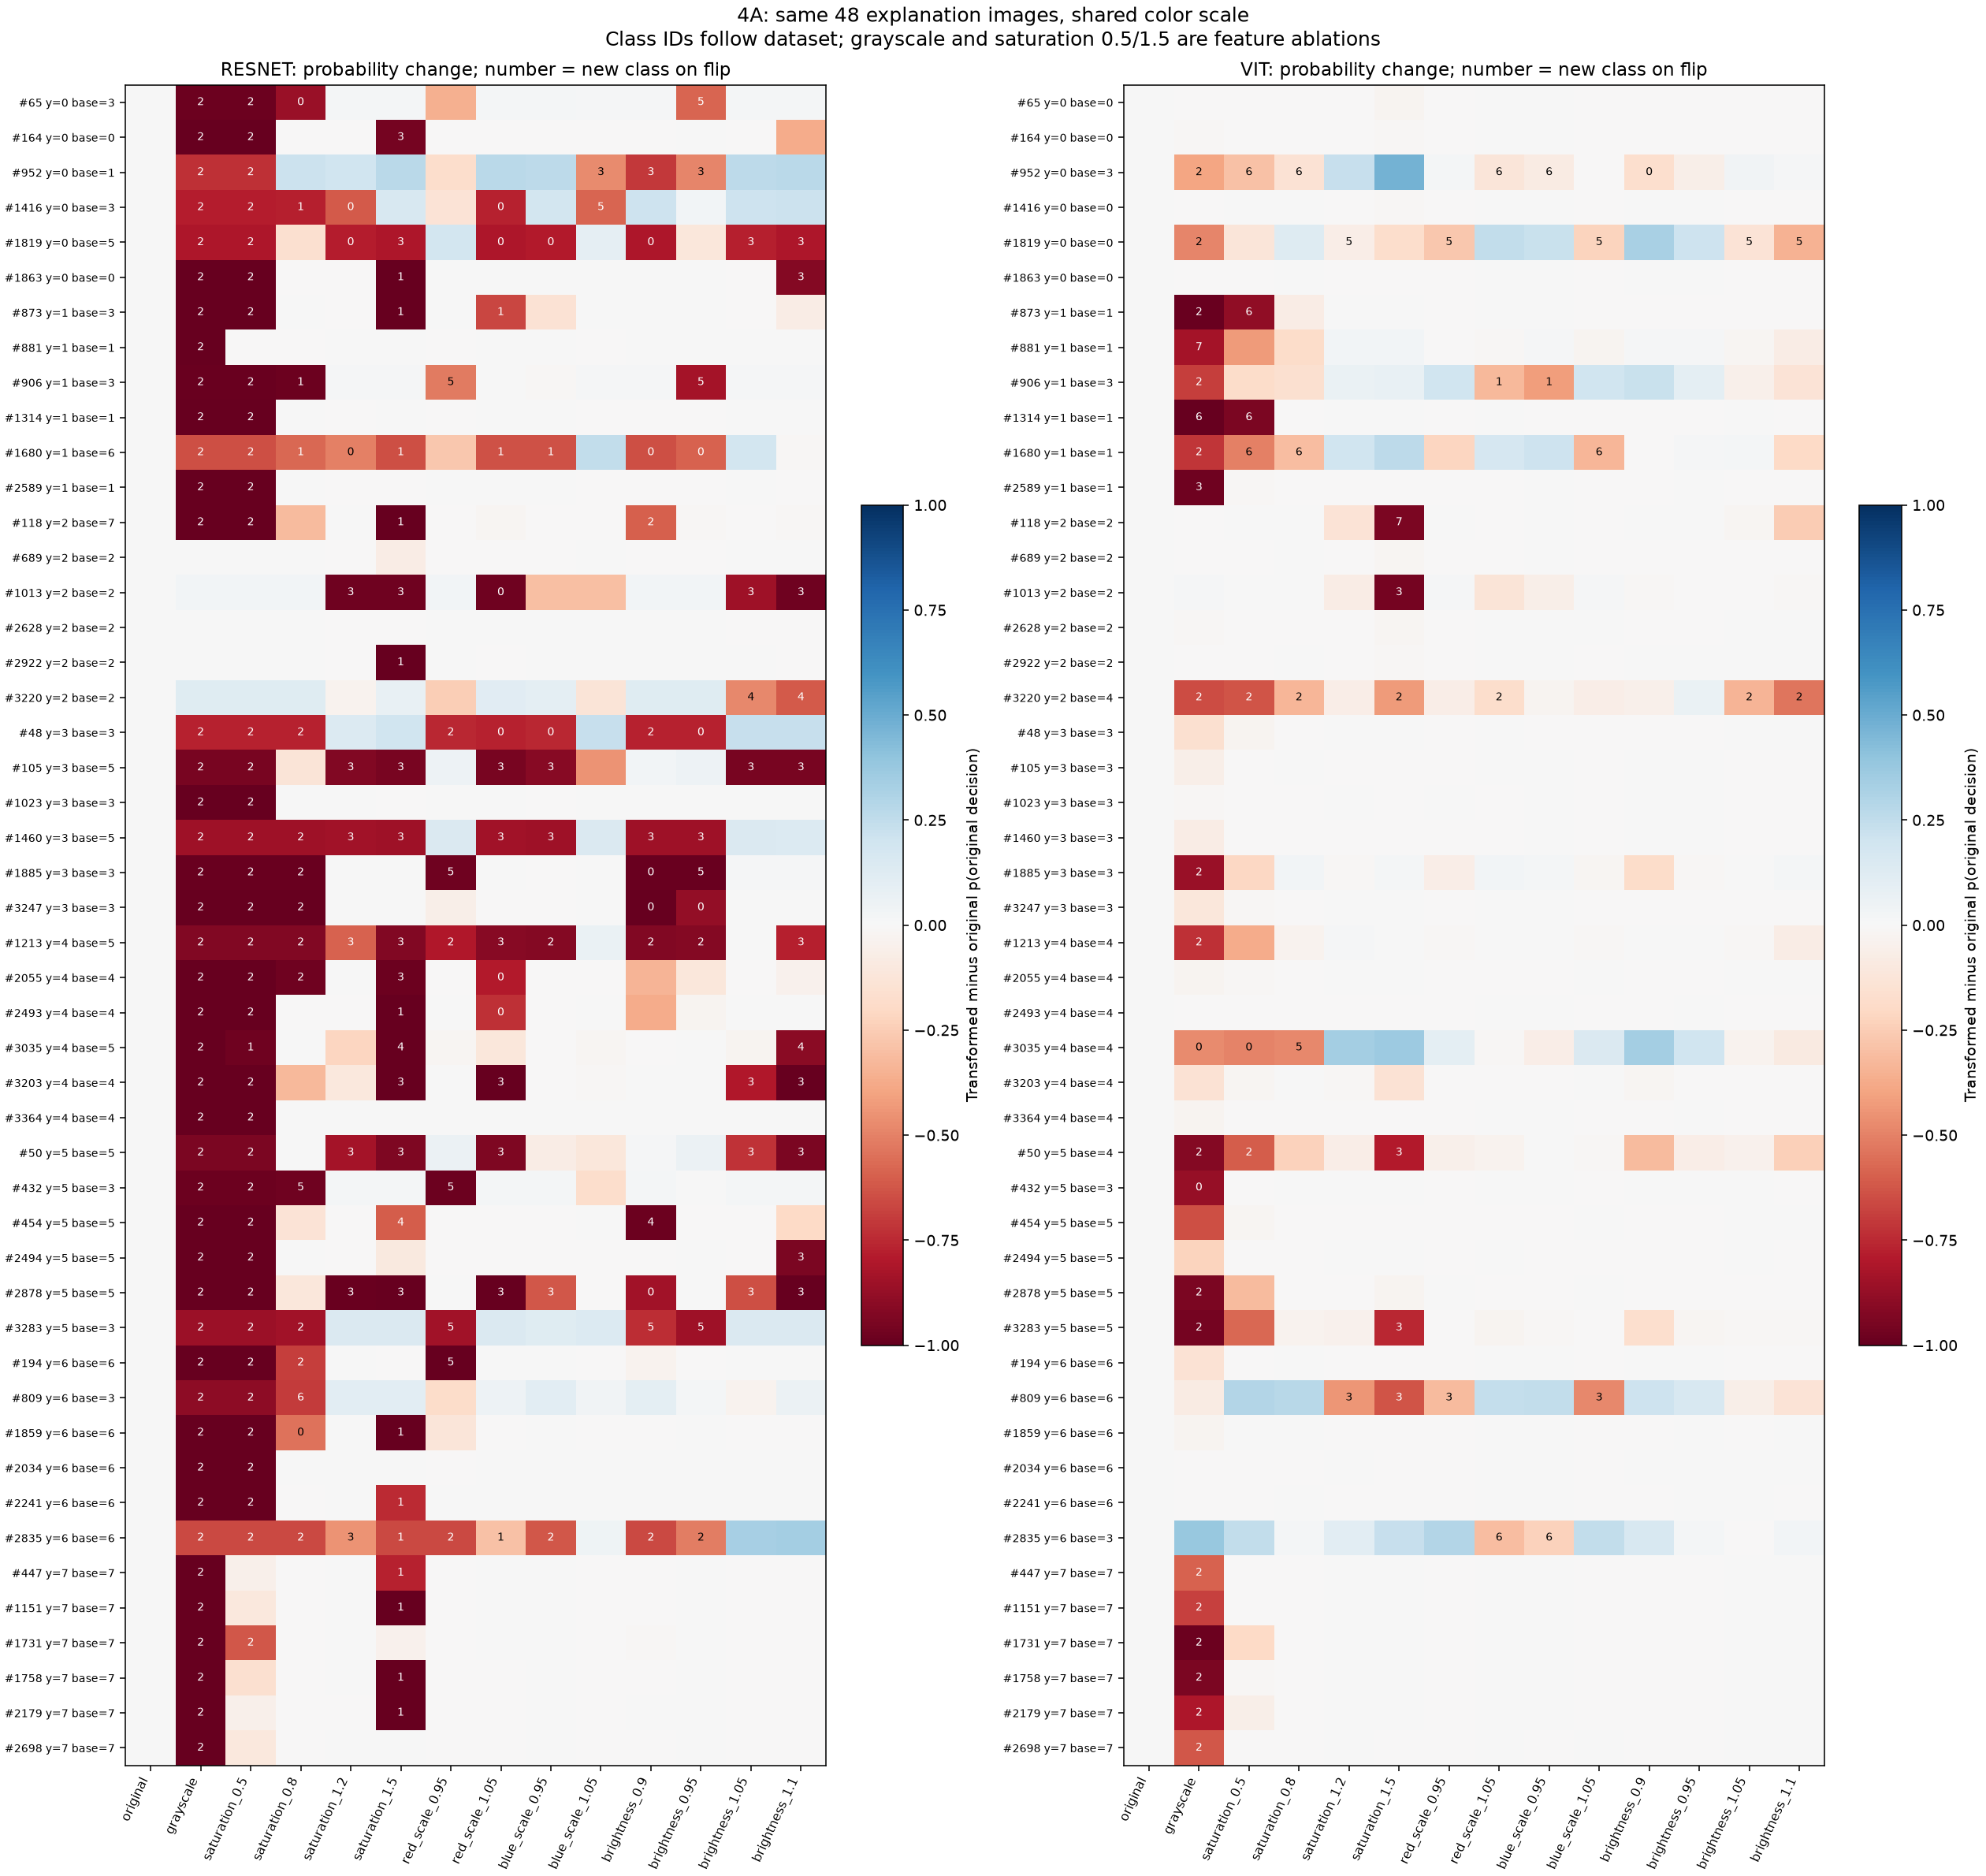

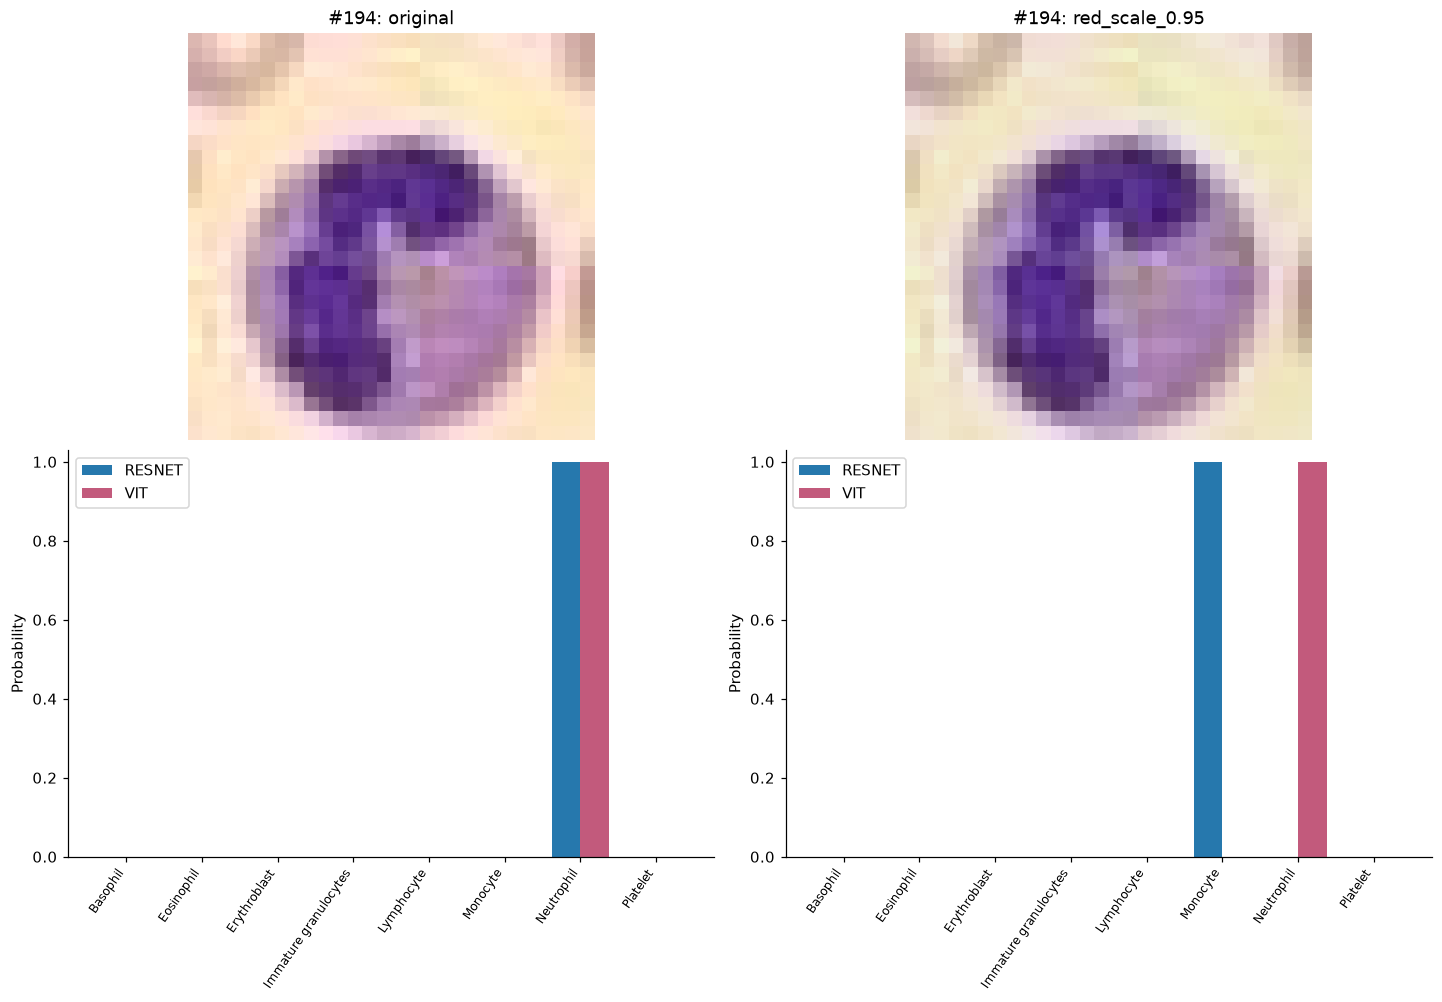

,model,transformation,true_label,baseline_prediction,prediction,retained_baseline_probability,true_class_probability_change
6,resnet,original,6,6,6,0.9993,0.0000e+00
294,resnet,red_scale_0.95,6,6,5,0.0002,-9.9910e-01
678,vit,original,6,6,6,0.9997,0.0000e+00
966,vit,red_scale_0.95,6,6,6,0.9997,-5.5015e-05


In [13]:
saved_figure("results/color_background/figures/color_probability_matrix.png",width=1400)
# Inspect a shared-target, initially-correct small-channel example from the raw cache.
example_id=194
with np.load(RESULTS/"color_background/interventions/color/red_scale_0.95.npz",allow_pickle=False) as z:
    example_image=z["images"][np.flatnonzero(z["sample_index"]==example_id)[0]]
fig,axes=plt.subplots(2,2,figsize=(13,9),layout="constrained")
for col,(key,image) in enumerate((("original",test_images[example_id]),("red_scale_0.95",example_image))):
    axes[0,col].imshow(image); axes[0,col].axis("off"); axes[0,col].set_title(f"#{example_id}: {key}")
    q=color[(color.sample_index==example_id)&(color.transformation==key)]
    for offset,f in zip((-.19,.19),MODELS):
        r=q[q.model==f].iloc[0]; prob=np.array(json.loads(r.probabilities))
        axes[1,col].bar(np.arange(8)+offset,prob,width=.38,label=f.upper(),color=COLORS[f])
    axes[1,col].set(xticks=range(8),xticklabels=SHORT,ylabel="Probability",ylim=(0,1.03))
    plt.setp(axes[1,col].get_xticklabels(),rotation=55,ha="right",fontsize=8)
    axes[1,col].legend()
plt.show()
display(color[(color.sample_index==example_id)&color.transformation.isin(["original","red_scale_0.95"])][
    ["model","transformation","true_label","baseline_prediction","prediction","retained_baseline_probability","true_class_probability_change"]])

## 7. Experiment 4B: central region versus periphery

The 16 masks were visually checked by the coding assistant, **not a human/clinical annotator**. Ellipses are approximate, and the periphery may contain other cells. Whole-region grayscale/blur has unequal area/intensity and is not a fair standalone central/background comparison.

Use the matched controls: equal nonzero pixel count and RGB intensity per pair, three spatial repeats averaged within image, and **true-class probability** as a shared target. Exact budgets still do not equate texture, context, semantic importance or contiguity.

Mask review: Coding assistant: visual inspection of original 48-image contact sheet and all 16 original/contour/intervention preview rows; not a clinical expert or human reviewer.
Scope: Approximate geometric central-cell regions, not expert biological segmentation. Peripheral regions can contain other cells.


images  mean_abs_true_class_change  \
model  magnitude region                                           
resnet 8         central         16                      0.0442   
                 peripheral      16                      0.0212   
       16        central         16                      0.1714   
                 peripheral      16                      0.0439   
vit    8         central         16                      0.0247   
                 peripheral      16                      0.0134   
       16        central         16                      0.0794   
                 peripheral      16                      0.0351   

                             median_abs_true_class_change  mean_flip_fraction  
model  magnitude region                                                        
resnet 8         central                           0.0068              0.0312  
                 peripheral                        0.0016              0.0000  
       16        central                           0.0593              0.1875  
                 peripheral                        0.0028              0.0312  
vit    8         central                           0.0003              0.0312  
                 peripheral                        0.0001              0.0104  
       16        central                           0.0006              0.0521  
                 peripheral                        0.0003              0.0417

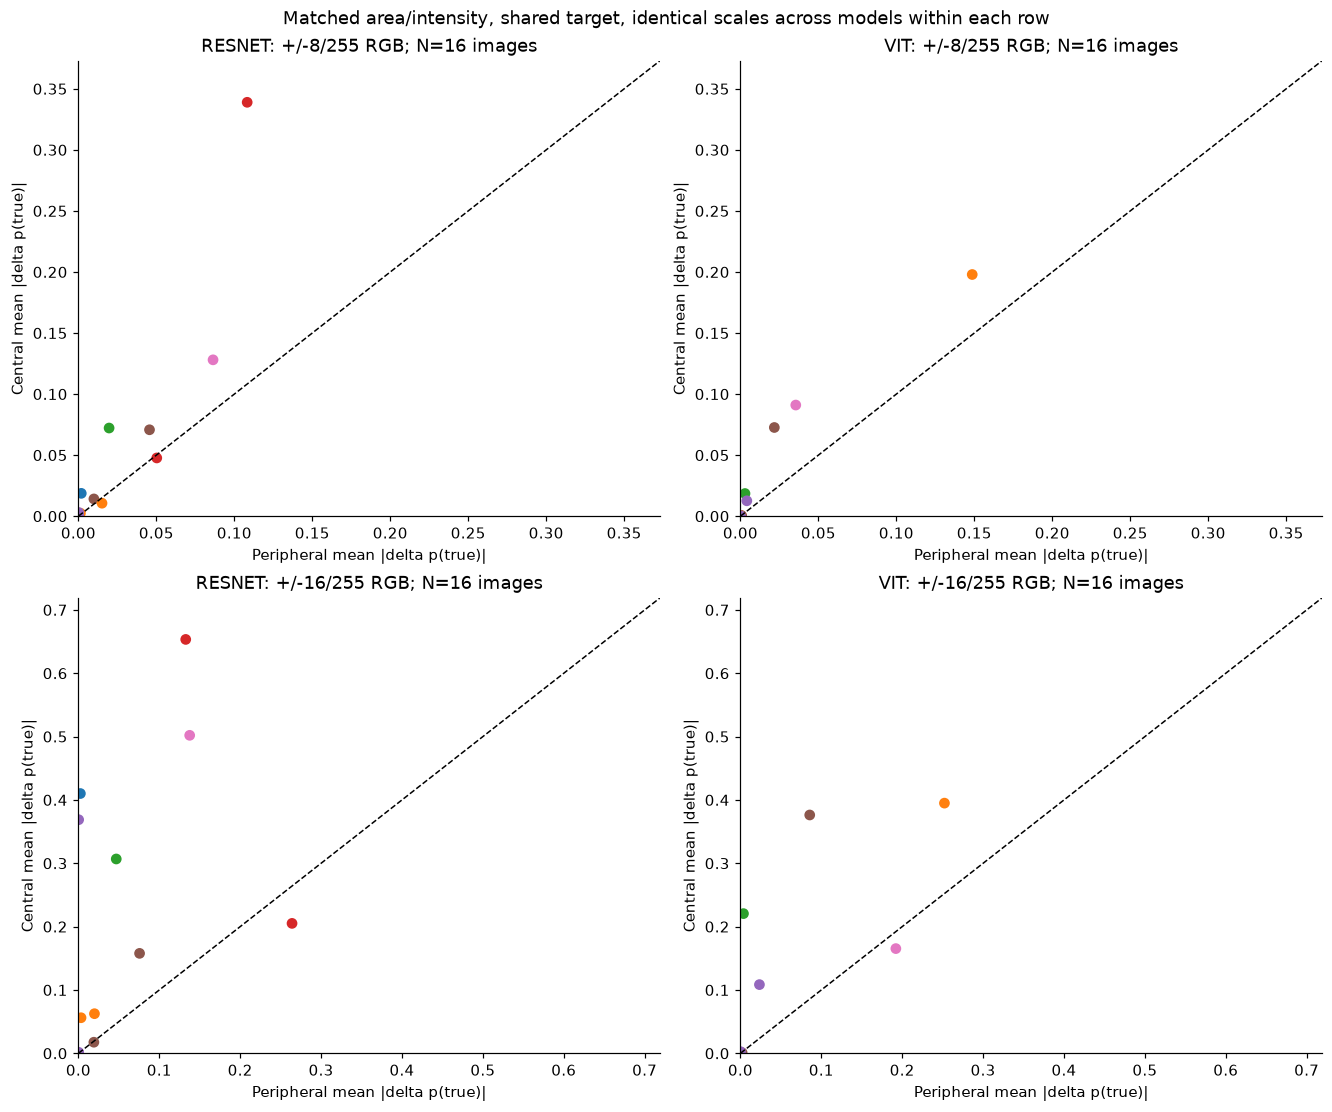

All matched pairs have equal budgets; spatial repeats were not treated as independent images.


In [14]:
review=read_json("results/color_background/masks/review.json")
print("Mask review:",review["reviewer"])
print("Scope:",review["scope"])
matched=regions[regions.design=="matched"].copy()
assert (regions.outside_selected_changed_pixels==0).all()
assert (matched.selected_pixels==matched.actually_changed_pixels).all()
budget_keys=["sample_index","model","delta","repeat"]
for metric in ("selected_pixels","actually_changed_pixels","l1_rgb_total","rms_rgb_change_whole_image"):
    span=matched.groupby(budget_keys)[metric].agg(["min","max"])
    np.testing.assert_allclose(span["min"],span["max"],atol=0,rtol=0)
matched["abs_true_class_change"]=matched.true_class_probability_change.abs()
within_image=matched.groupby(["sample_index","model","region","delta"],as_index=False).agg(
    abs_change=("abs_true_class_change","mean"),flip_fraction=("label_flipped","mean"))
within_image["magnitude"]=within_image.delta.abs()
# Average signs AFTER averaging spatial repeats; one value per image/region/magnitude.
matched_images=within_image.groupby(["sample_index","model","region","magnitude"],as_index=False).agg(
    abs_change=("abs_change","mean"),flip_fraction=("flip_fraction","mean"))
matched_summary=matched_images.groupby(["model","magnitude","region"]).agg(
    images=("sample_index","nunique"),mean_abs_true_class_change=("abs_change","mean"),
    median_abs_true_class_change=("abs_change","median"),mean_flip_fraction=("flip_fraction","mean"))
display(matched_summary)
fig,axes=plt.subplots(2,2,figsize=(12,10),layout="constrained")
for row,magnitude in enumerate((8,16)):
    q=matched_images[matched_images.magnitude==magnitude]
    scale=max(q.abs_change.max()*1.1,.01)
    for col,f in enumerate(MODELS):
        pair=q[q.model==f].pivot(index="sample_index",columns="region",values="abs_change")
        ax=axes[row,col]
        cls=all_test.loc[pair.index,"true_label"]
        ax.scatter(pair.peripheral,pair.central,c=cls,cmap="tab10",vmin=0,vmax=9)
        ax.plot([0,scale],[0,scale],"k--",lw=1)
        ax.set(xlim=(0,scale),ylim=(0,scale),xlabel="Peripheral mean |delta p(true)|",ylabel="Central mean |delta p(true)|",
               title=f"{f.upper()}: +/-{magnitude}/255 RGB; N={len(pair)} images")
fig.suptitle("Matched area/intensity, shared target, identical scales across models within each row")
plt.show()
print("All matched pairs have equal budgets; spatial repeats were not treated as independent images.")

### Means can hide concentrated vulnerabilities

Inspect image-level values and medians, not only a mean central/peripheral contrast. The 16-image region set has only eight initially-both-correct images; conditioning changes its class mix too. Absolute probability change includes increases and decreases, so it is sensitivity rather than harm. The top-contributor calculation below is descriptive concentration on this set, not population prevalence.

mean_abs_true_change  \
both_correct model  magnitude region                             
False        resnet 8         central                   0.0366   
                              peripheral                0.0263   
                    16        central                   0.1766   
                              peripheral                0.0653   
             vit    8         central                   0.0469   
                              peripheral                0.0264   
                    16        central                   0.1309   
                              peripheral                0.0696   
True         resnet 8         central                   0.0518   
                              peripheral                0.0160   
                    16        central                   0.1662   
                              peripheral                0.0225   
             vit    8         central                   0.0024   
                              peripheral                0.0004   
                    16        central                   0.0280   
                              peripheral                0.0005   

                                          median_abs_true_change  \
both_correct model  magnitude region                               
False        resnet 8         central                 1.6414e-02   
                              peripheral              1.2535e-02   
                    16        central                 1.1016e-01   
                              peripheral              1.9475e-02   
             vit    8         central                 6.5403e-03   
                              peripheral              2.3977e-03   
                    16        central                 5.4699e-02   
                              peripheral              1.2804e-02   
True         resnet 8         central                 1.3185e-04   
                              peripheral              7.5564e-05   
                    16        central                 2.9250e-04   
                              peripheral              1.7264e-04   
             vit    8         central                 5.4051e-05   
                              peripheral              1.7871e-05   
                    16        central                 1.2348e-04   
                              peripheral              5.5119e-05   

                                          unique_images  
both_correct model  magnitude region                     
False        resnet 8         central                 8  
                              peripheral              8  
                    16        central                 8  
                              peripheral              8  
             vit    8         central                 8  
                              peripheral              8  
                    16        central                 8  
                              peripheral              8  
True         resnet 8         central                 8  
                              peripheral              8  
                    16        central                 8  
                              peripheral              8  
             vit    8         central                 8  
                              peripheral              8  
                    16        central                 8  
                              peripheral              8

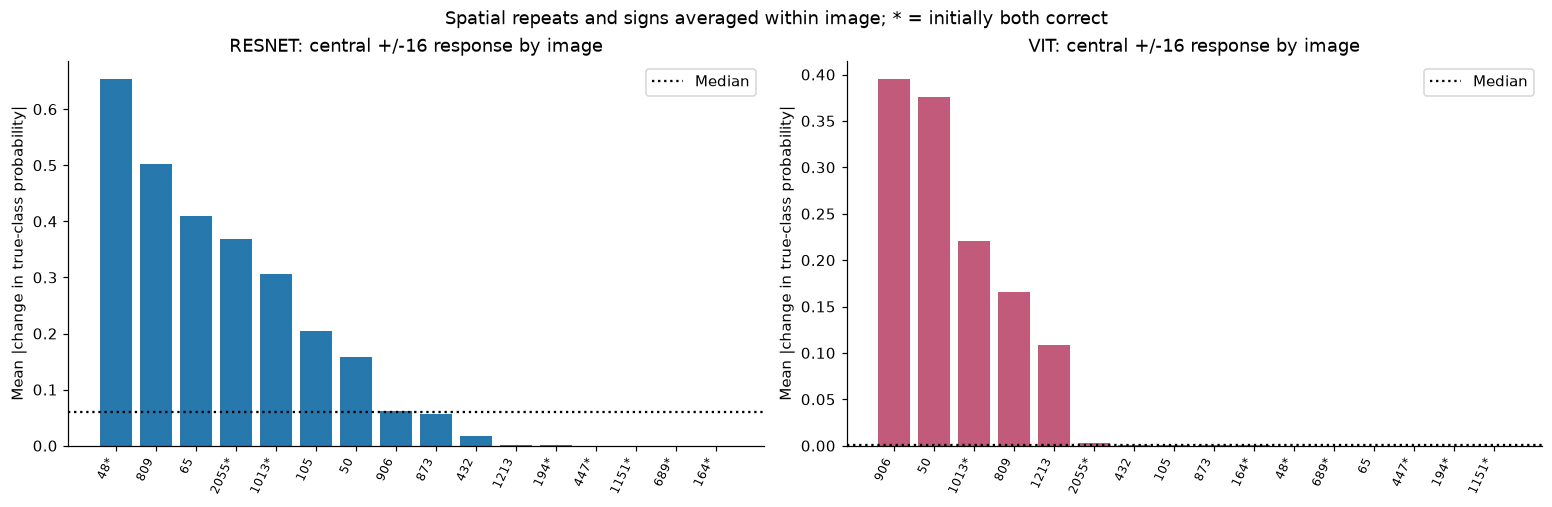

,top_three_share,top_three_IDs,mean,median,n_images
model,,,,,
resnet,0.5709,"[48, 809, 65]",0.1714,0.0593,16
vit,0.7802,"[906, 50, 1013]",0.0794,0.0006,16


In [15]:
regional_context=matched_images.copy()
regional_context["both_correct"]=regional_context.sample_index.map((all_test.group=="both_correct").to_dict())
display(regional_context.groupby(["both_correct","model","magnitude","region"]).agg(
    mean_abs_true_change=("abs_change","mean"),median_abs_true_change=("abs_change","median"),
    unique_images=("sample_index","nunique")))
fig,axes=plt.subplots(1,2,figsize=(14,4.5),layout="constrained")
concentration=[]
for ax,f in zip(axes,MODELS):
    q=regional_context[(regional_context.model==f)&(regional_context.region=="central")&
                        (regional_context.magnitude==16)].sort_values("abs_change",ascending=False)
    share=q.head(3).abs_change.sum()/q.abs_change.sum()
    concentration.append({"model":f,"top_three_share":share,"top_three_IDs":q.head(3).sample_index.tolist(),
                           "mean":q.abs_change.mean(),"median":q.abs_change.median(),"n_images":len(q)})
    ax.bar(range(len(q)),q.abs_change,color=COLORS[f])
    ax.set(xticks=range(len(q)),xticklabels=[str(r.sample_index)+( "*" if r.both_correct else "") for r in q.itertuples()],
           title=f"{f.upper()}: central +/-16 response by image",ylabel="Mean |change in true-class probability|")
    plt.setp(ax.get_xticklabels(),rotation=65,ha="right",fontsize=8)
    ax.axhline(q.abs_change.median(),color="black",linestyle=":",label="Median")
    ax.legend()
fig.suptitle("Spatial repeats and signs averaged within image; * = initially both correct")
plt.show()
display(pd.DataFrame(concentration).set_index("model"))

mean_selected_area    mean_L1  \
model  operation region                                      
resnet blur      central                  287.5  19034.375   
                 peripheral               496.5  18068.500   
       grayscale central                  287.5  21825.500   
                 peripheral               496.5  26318.625   
vit    blur      central                  287.5  19034.375   
                 peripheral               496.5  18068.500   
       grayscale central                  287.5  21825.500   
                 peripheral               496.5  26318.625   

                             mean_abs_true_class_change  
model  operation region                                  
resnet blur      central                         0.3816  
                 peripheral                      0.2154  
       grayscale central                         0.4328  
                 peripheral                      0.3417  
vit    blur      central                         0.5141  
                 peripheral                      0.2100  
       grayscale central                         0.3792  
                 peripheral                      0.2845

Do not fix the unequal-budget problem by simply dividing probability change by area; the response is nonlinear.


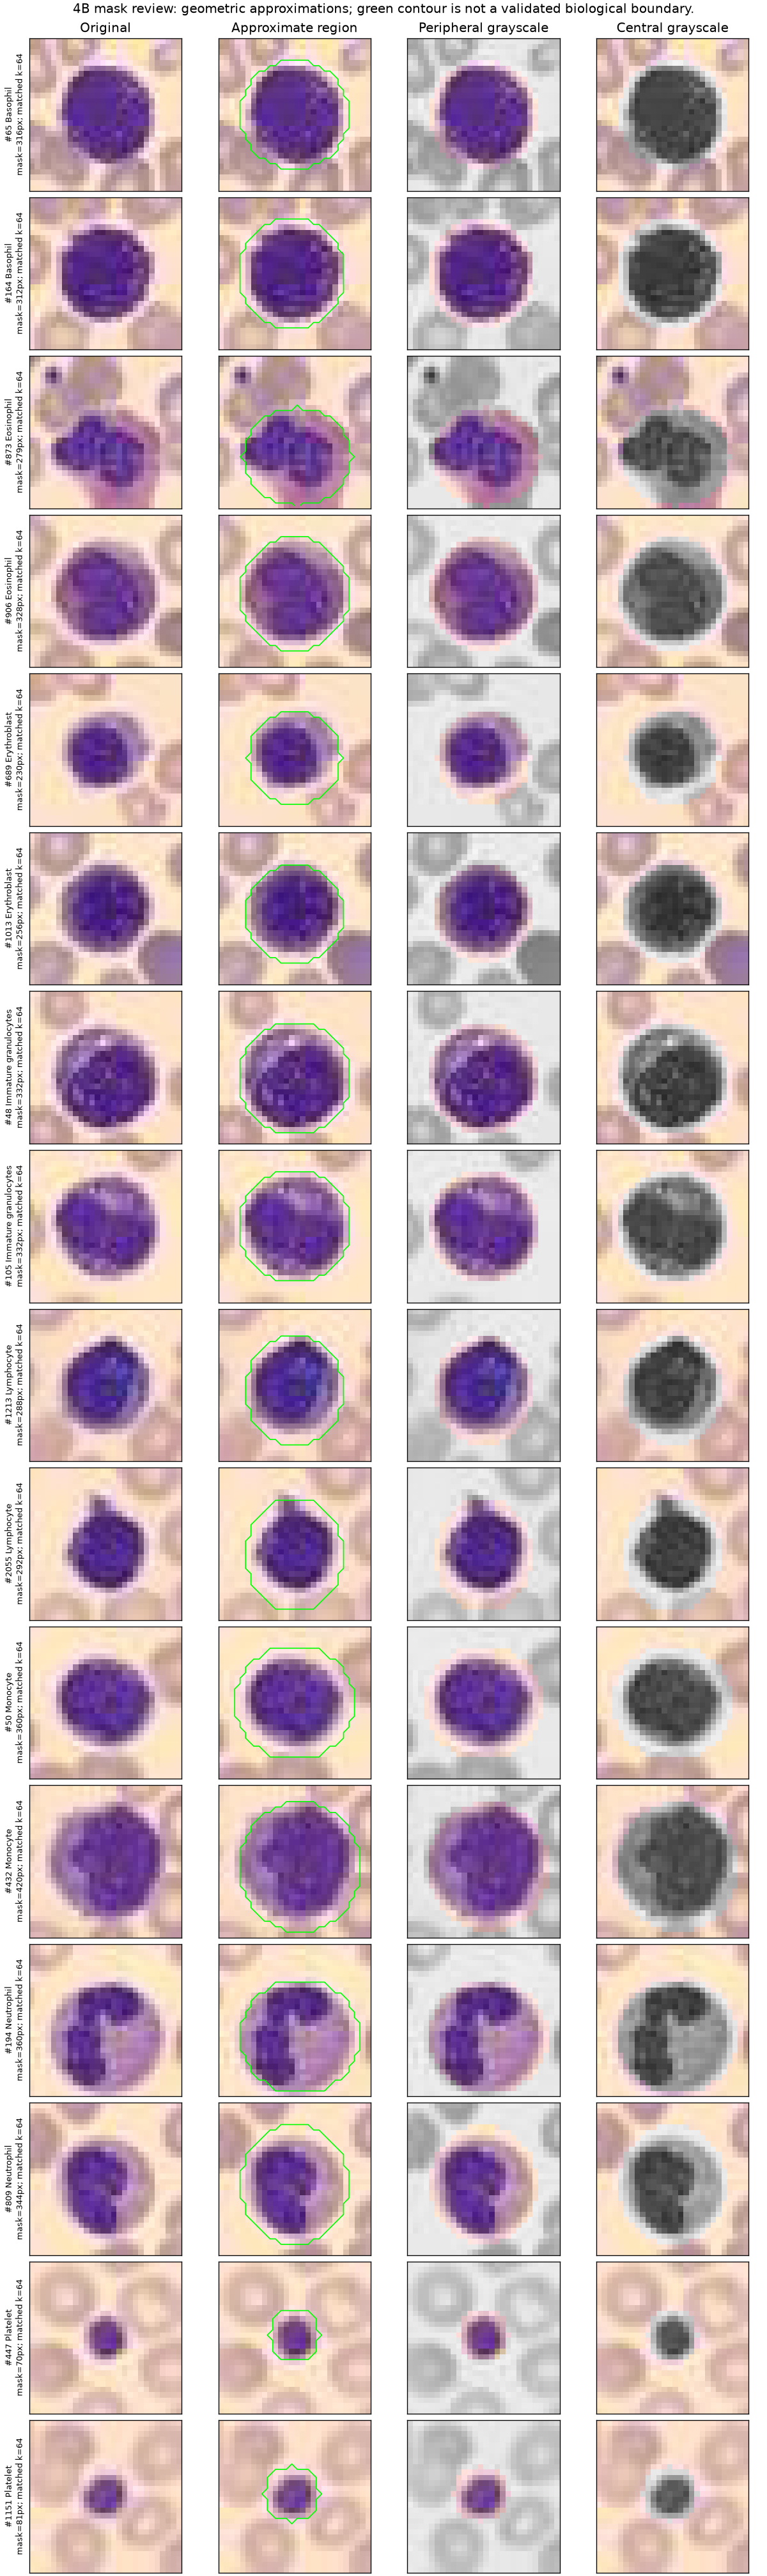

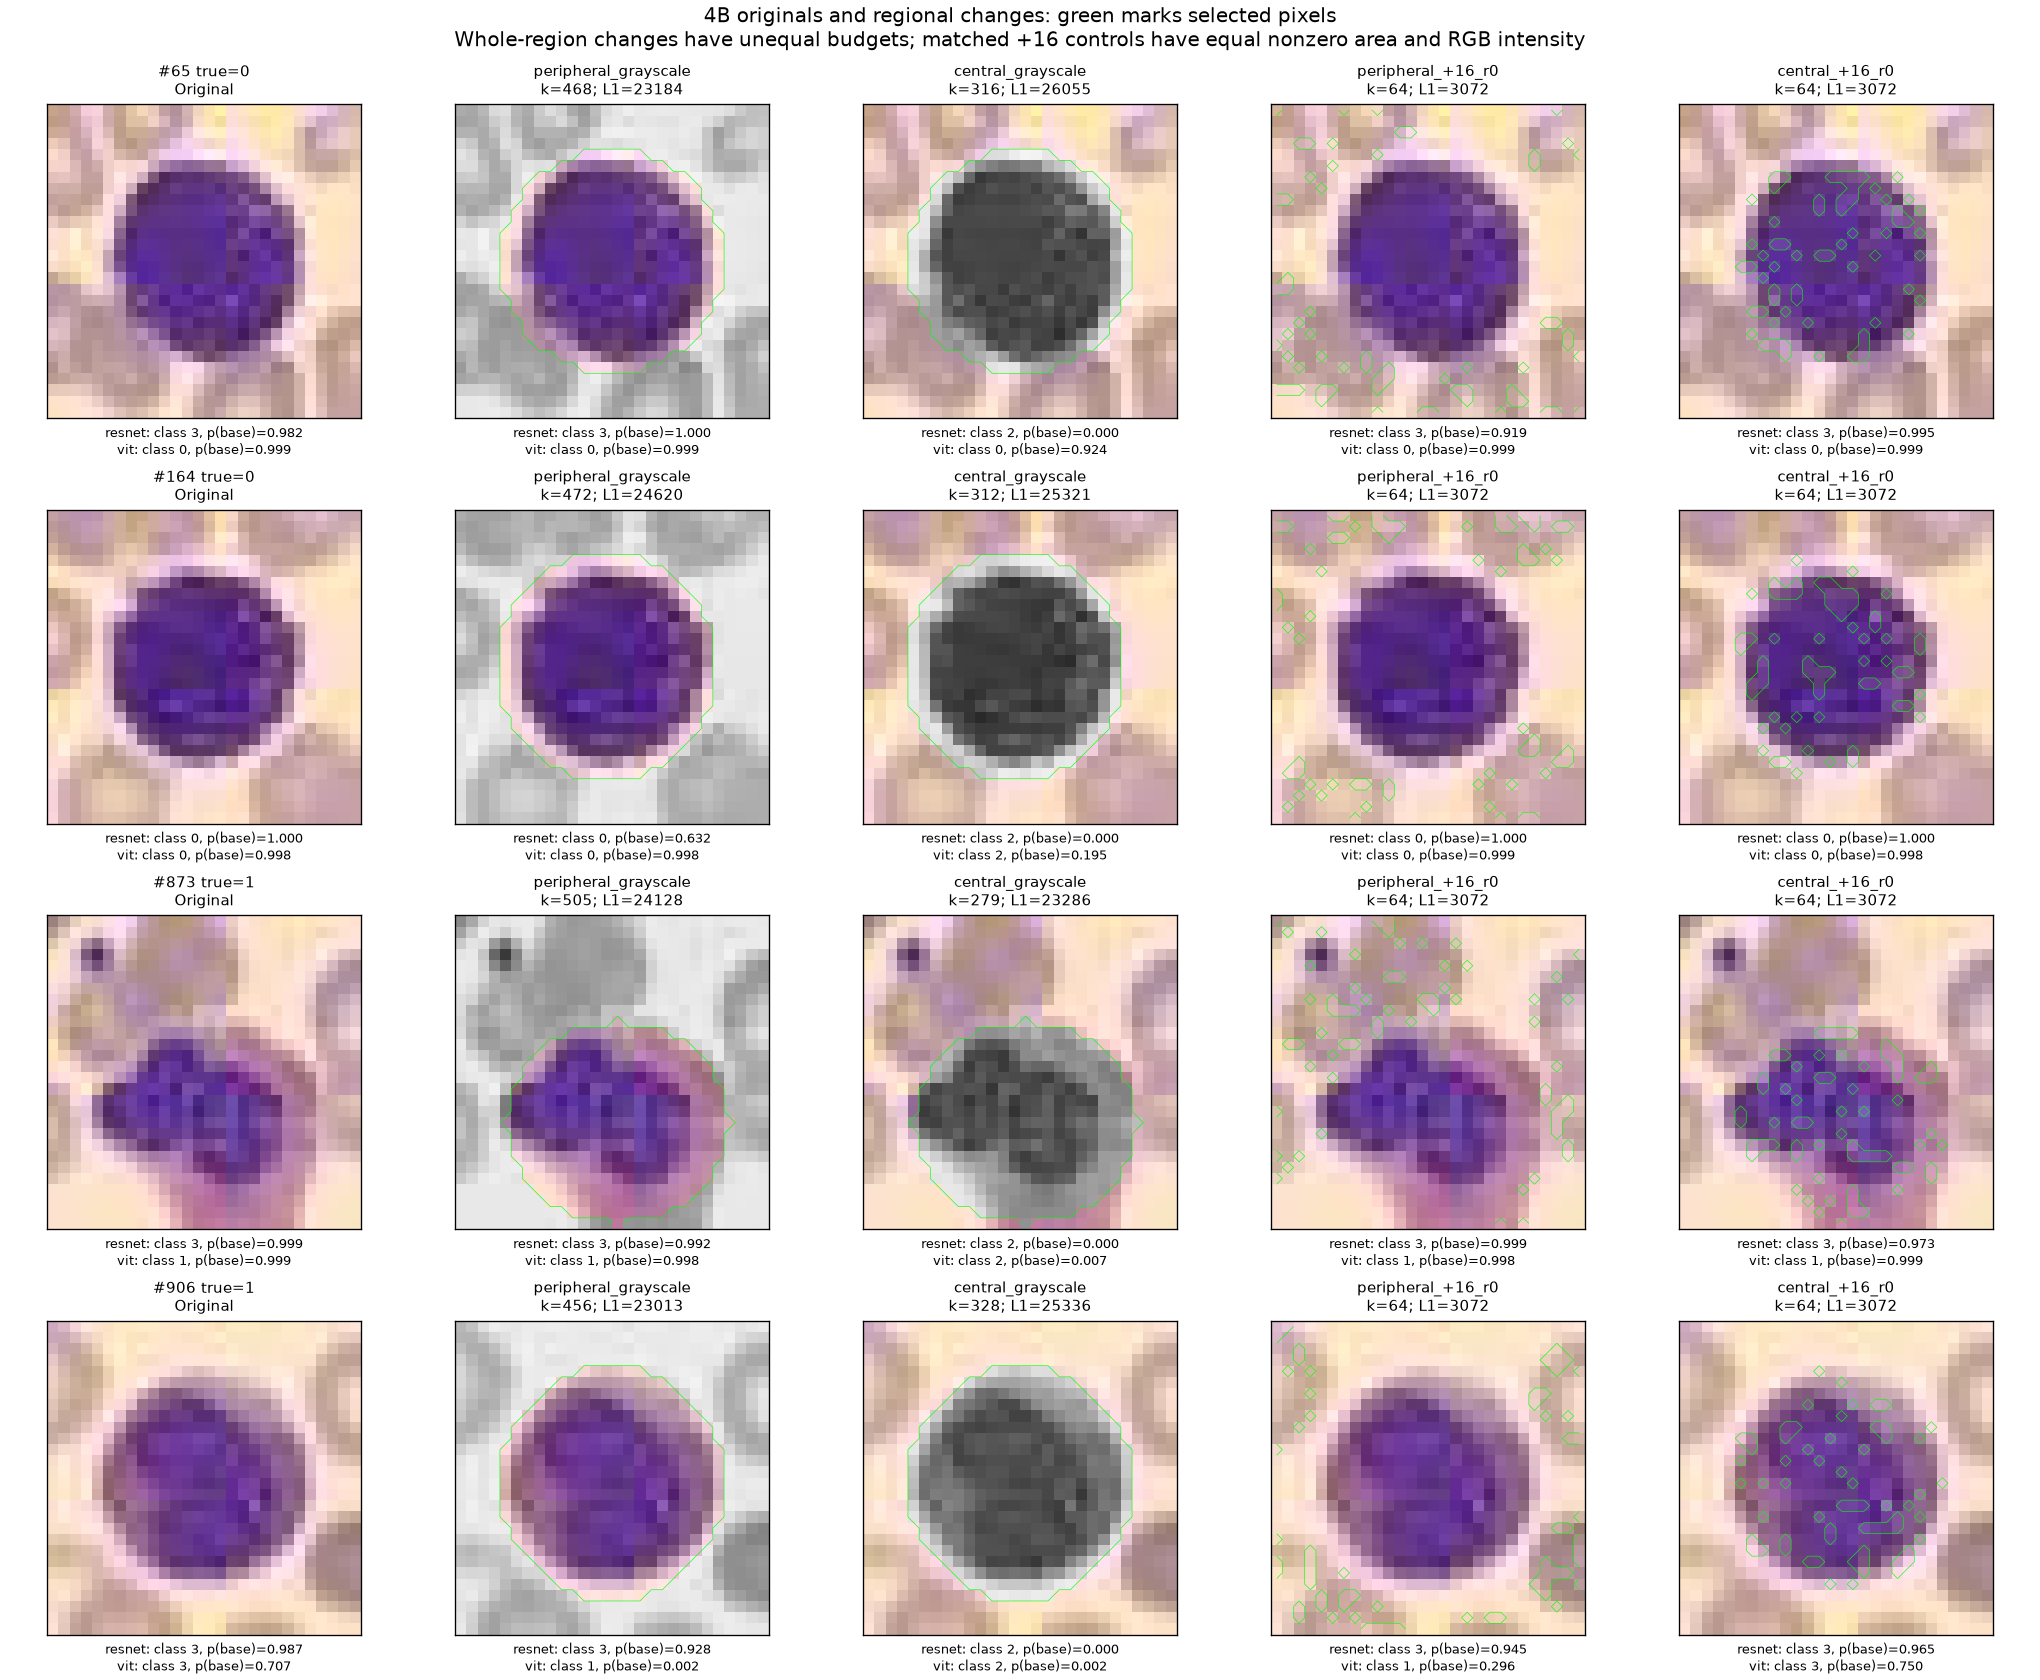

In [16]:
whole=regions[regions.design=="whole_region"].copy()
whole["abs_true_class_change"]=whole.true_class_probability_change.abs()
display(whole.groupby(["model","operation","region"]).agg(
    mean_selected_area=("selected_pixels","mean"),mean_L1=("l1_rgb_total","mean"),
    mean_abs_true_class_change=("abs_true_class_change","mean")))
print("Do not fix the unequal-budget problem by simply dividing probability change by area; the response is nonlinear.")
saved_figure("results/color_background/pilot/masks.png",width=650)
# Includes all 16 images across four pages in the saved atlas; show one page here.
saved_figure("results/color_background/figures/region_examples_01.png",width=1300)

## 8. Experiment 5: finite-grid counterfactual paths

Selection used Experiments 1-4 **before E5 inference**, but is deliberately qualitative. Search both signs and refine every observed transition from either model, not a unique monotonic boundary.

"Nearest" means nearest **observed** switched point. Same-class endpoints on the global scan can hide narrower islands. No observed switch is range/grid censoring, not a robustness certificate. Rotation degrees, shift pixels and general perturbation norms are different concepts.

**Important analysis trap:** the saved paths oversample transition neighborhoods. Do not average all saved rows to compare robustness. If comparing finite-range flip fractions, restrict to the common uniform global scan first.

In [17]:
display(pd.DataFrame(manifest_5["selection"])[["sample_index","experiment","selection_criterion","evidence"]])
comparison=nearest.pivot(index="sample_index",columns=["axis","model"],values="signed_value")
display(comparison)
print("NaN = no observed switch in the tested range/grid, NOT an infinite distance or a robustness certificate.")
print("Directional searches:",len(boundaries),"; no observed switch:",int((~boundaries.observed_switch).sum()))
print("Observed top-1 transitions:",len(transitions),"; returns to baseline:",int(transitions.returns_to_baseline.sum()))
# Verify each reported nearest value against every saved path point.
for r in nearest.itertuples():
    q=paths[(paths.sample_index==r.sample_index)&(paths.model==r.model)&(paths.axis==r.axis)&paths.label_flipped]
    assert (q.empty and pd.isna(r.absolute_value)) or (not q.empty and np.isclose(q.value.abs().min(),r.absolute_value))
config_5=read_json("results/counterfactual/config.json")
strides=paths.axis.map({axis:spec["scan_stride"] for axis,spec in config_5["axes"].items()}).to_numpy()
guard=paths[(paths.tick.to_numpy()%strides)==0]
uniform_fractions=guard.groupby(["sample_index","axis","model"]).label_flipped.mean().unstack("model")
display(uniform_fractions)
print("Finite-range fractions above use uniformly spaced points, not adaptive row density. Neither this nor a minimum is a global robustness score.")

,sample_index,experiment,selection_criterion,evidence
0,65,1,Largest probability-vector JS among different-...,JS=0.9932972866720883 bits; group=only_vit_cor...
1,105,3,Largest inter-model difference in peak absolut...,True-class occlusion peak |response|: ResNet=0...
2,194,4,Largest mild red/blue one-model-only response ...,red_scale_0.95; both initially correct; flips ...
3,432,3,Largest inter-model difference in peak absolut...,True-class occlusion peak |response|: ResNet=0...
4,809,2,Largest inter-model retained-probability gap u...,"rotation=-20; retained p(original): ResNet=1, ..."
5,906,1,Largest probability-vector JS among same-class...,JS=0.13220536273252806 bits; group=both_incorr...
6,2494,2,Largest inter-model retained-probability gap u...,translation=3; retained p(original): ResNet=3....
7,2878,4,Largest mild red/blue one-model-only response ...,red_scale_1.05; both initially correct; flips ...


axis         rotation         translation       
model          resnet     vit      resnet    vit
sample_index                                    
65             -0.425  26.450     -0.1000    NaN
105            -5.250   9.100      0.5125    NaN
194            12.900     NaN     -1.5000    NaN
432            -1.075  -8.125     -0.1625 -0.525
809               NaN  -1.600     -0.8500 -0.100
906             1.125   3.150      0.1875  0.775
2494           11.725     NaN     -2.0000    NaN
2878            5.025     NaN      0.6250    NaN

NaN = no observed switch in the tested range/grid, NOT an infinite distance or a robustness certificate.
Directional searches: 64 ; no observed switch: 24
Observed top-1 transitions: 137 ; returns to baseline: 57


model                     resnet     vit
sample_index axis                       
65           rotation     0.2905  0.0290
             translation  0.2449  0.0000
105          rotation     0.7759  0.2780
             translation  0.7755  0.0000
194          rotation     0.5477  0.0000
             translation  0.4694  0.0000
432          rotation     0.0664  0.5934
             translation  0.3878  0.1633
809          rotation     0.0000  0.9336
             translation  0.0612  0.7551
906          rotation     0.0747  0.0747
             translation  0.0612  0.3061
2494         rotation     0.5851  0.0000
             translation  0.1224  0.0000
2878         rotation     0.7220  0.0000
             translation  0.6735  0.0000

Finite-range fractions above use uniformly spaced points, not adaptive row density. Neither this nor a minimum is a global robustness score.


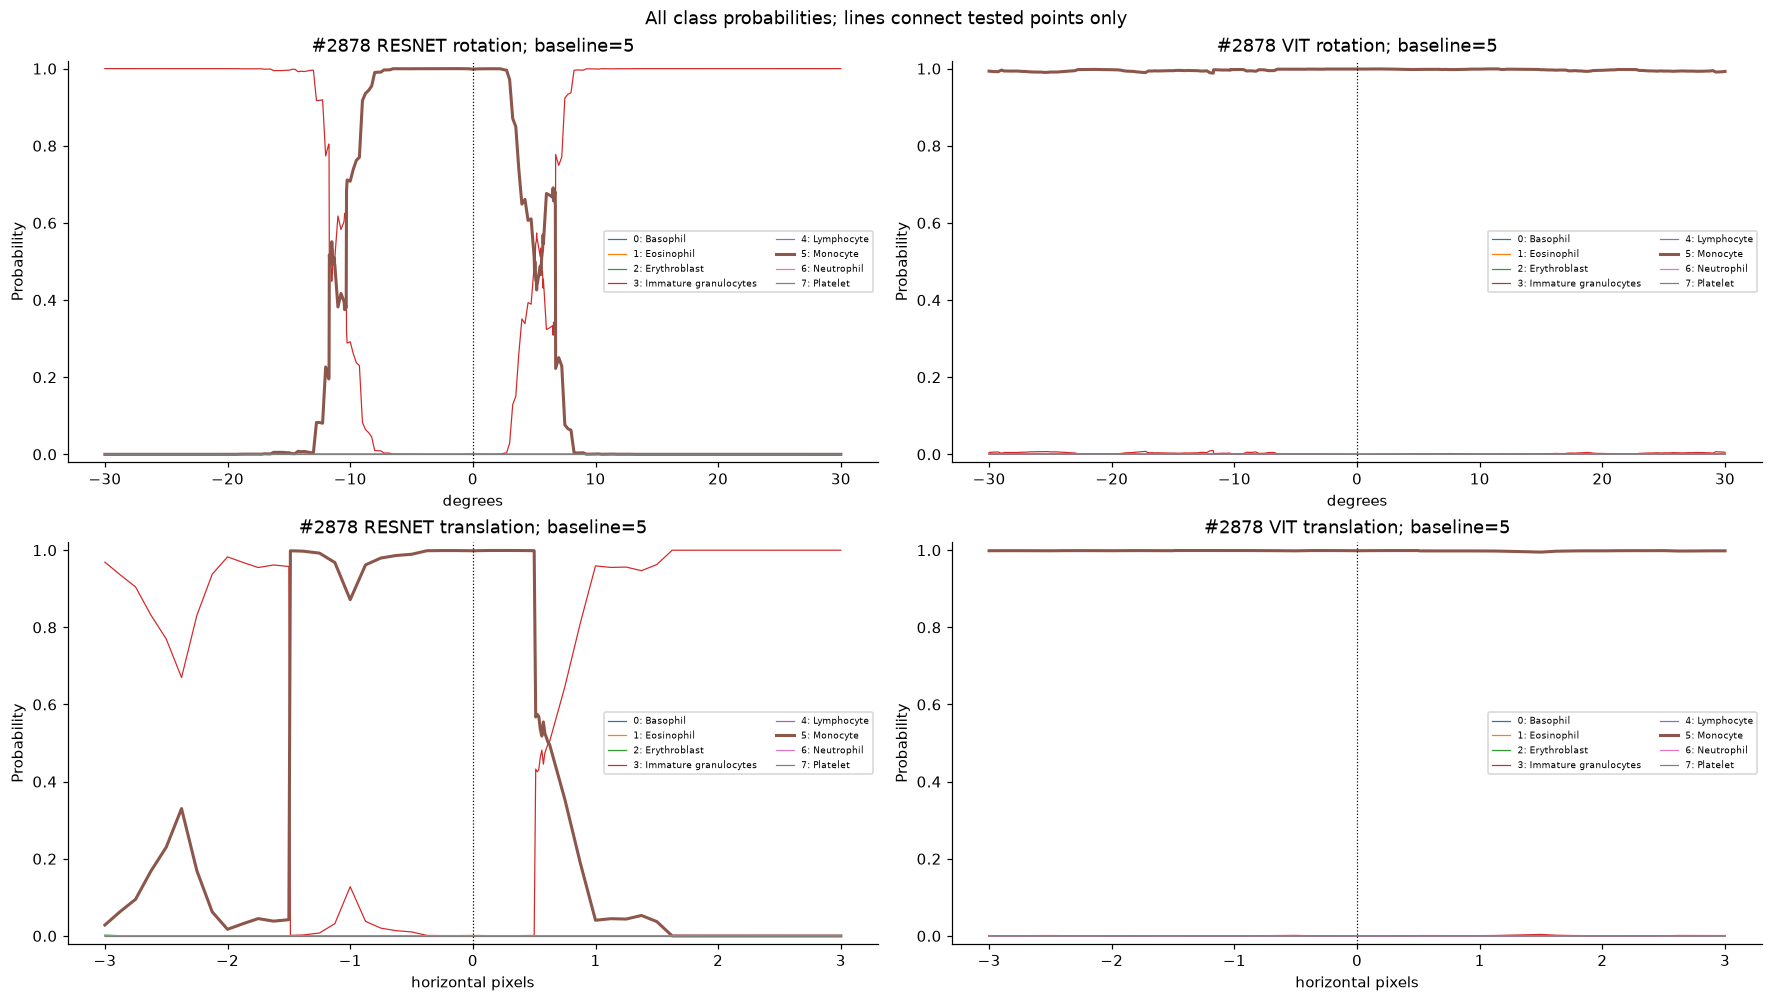

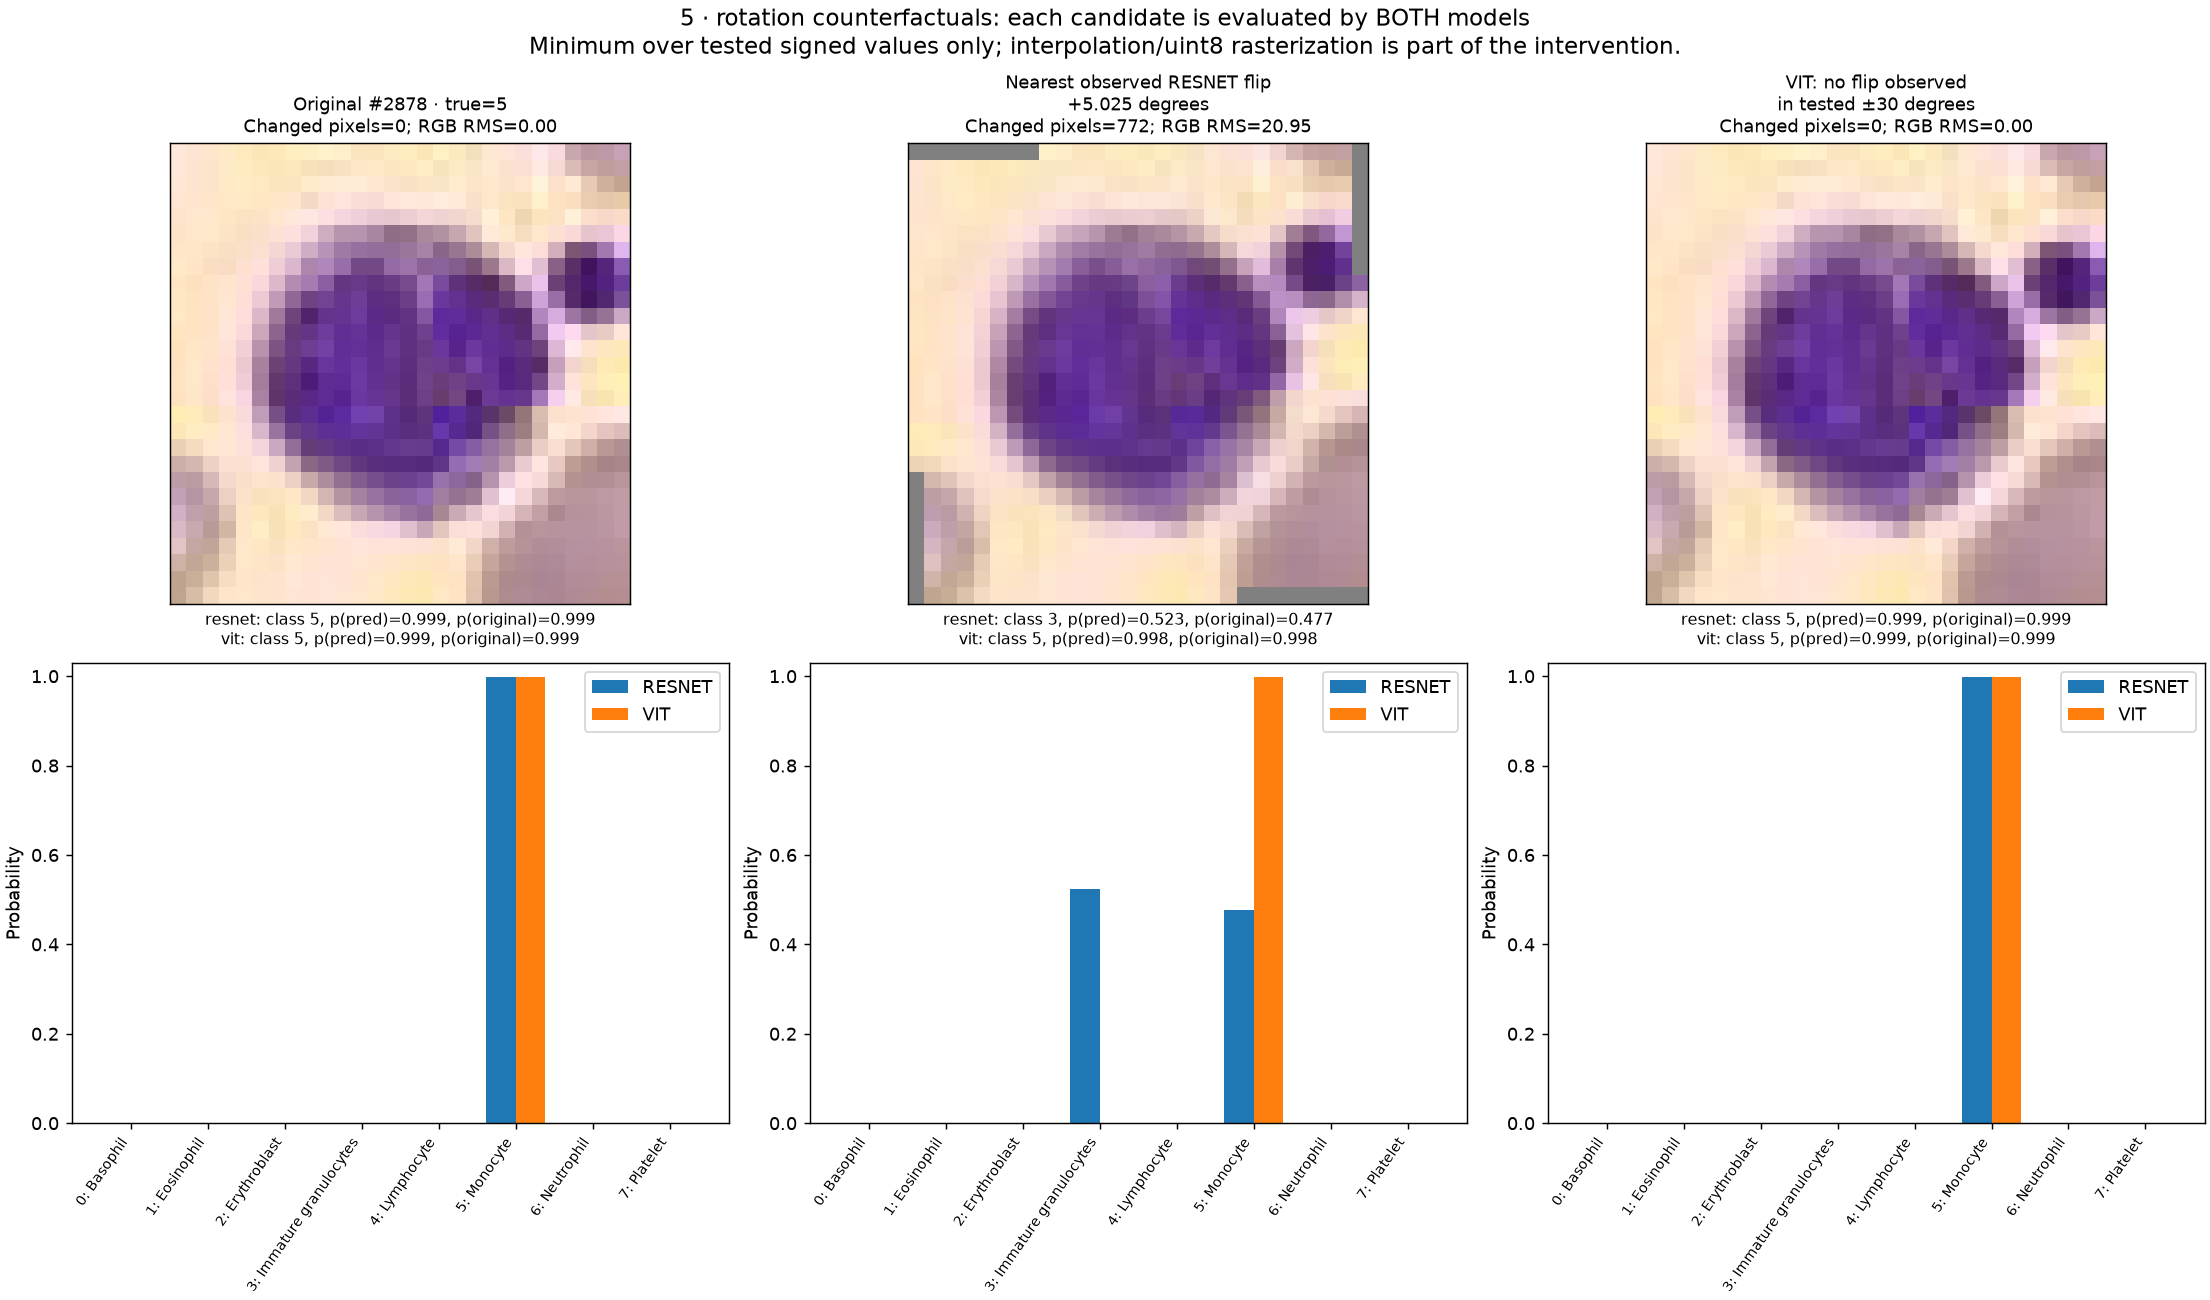

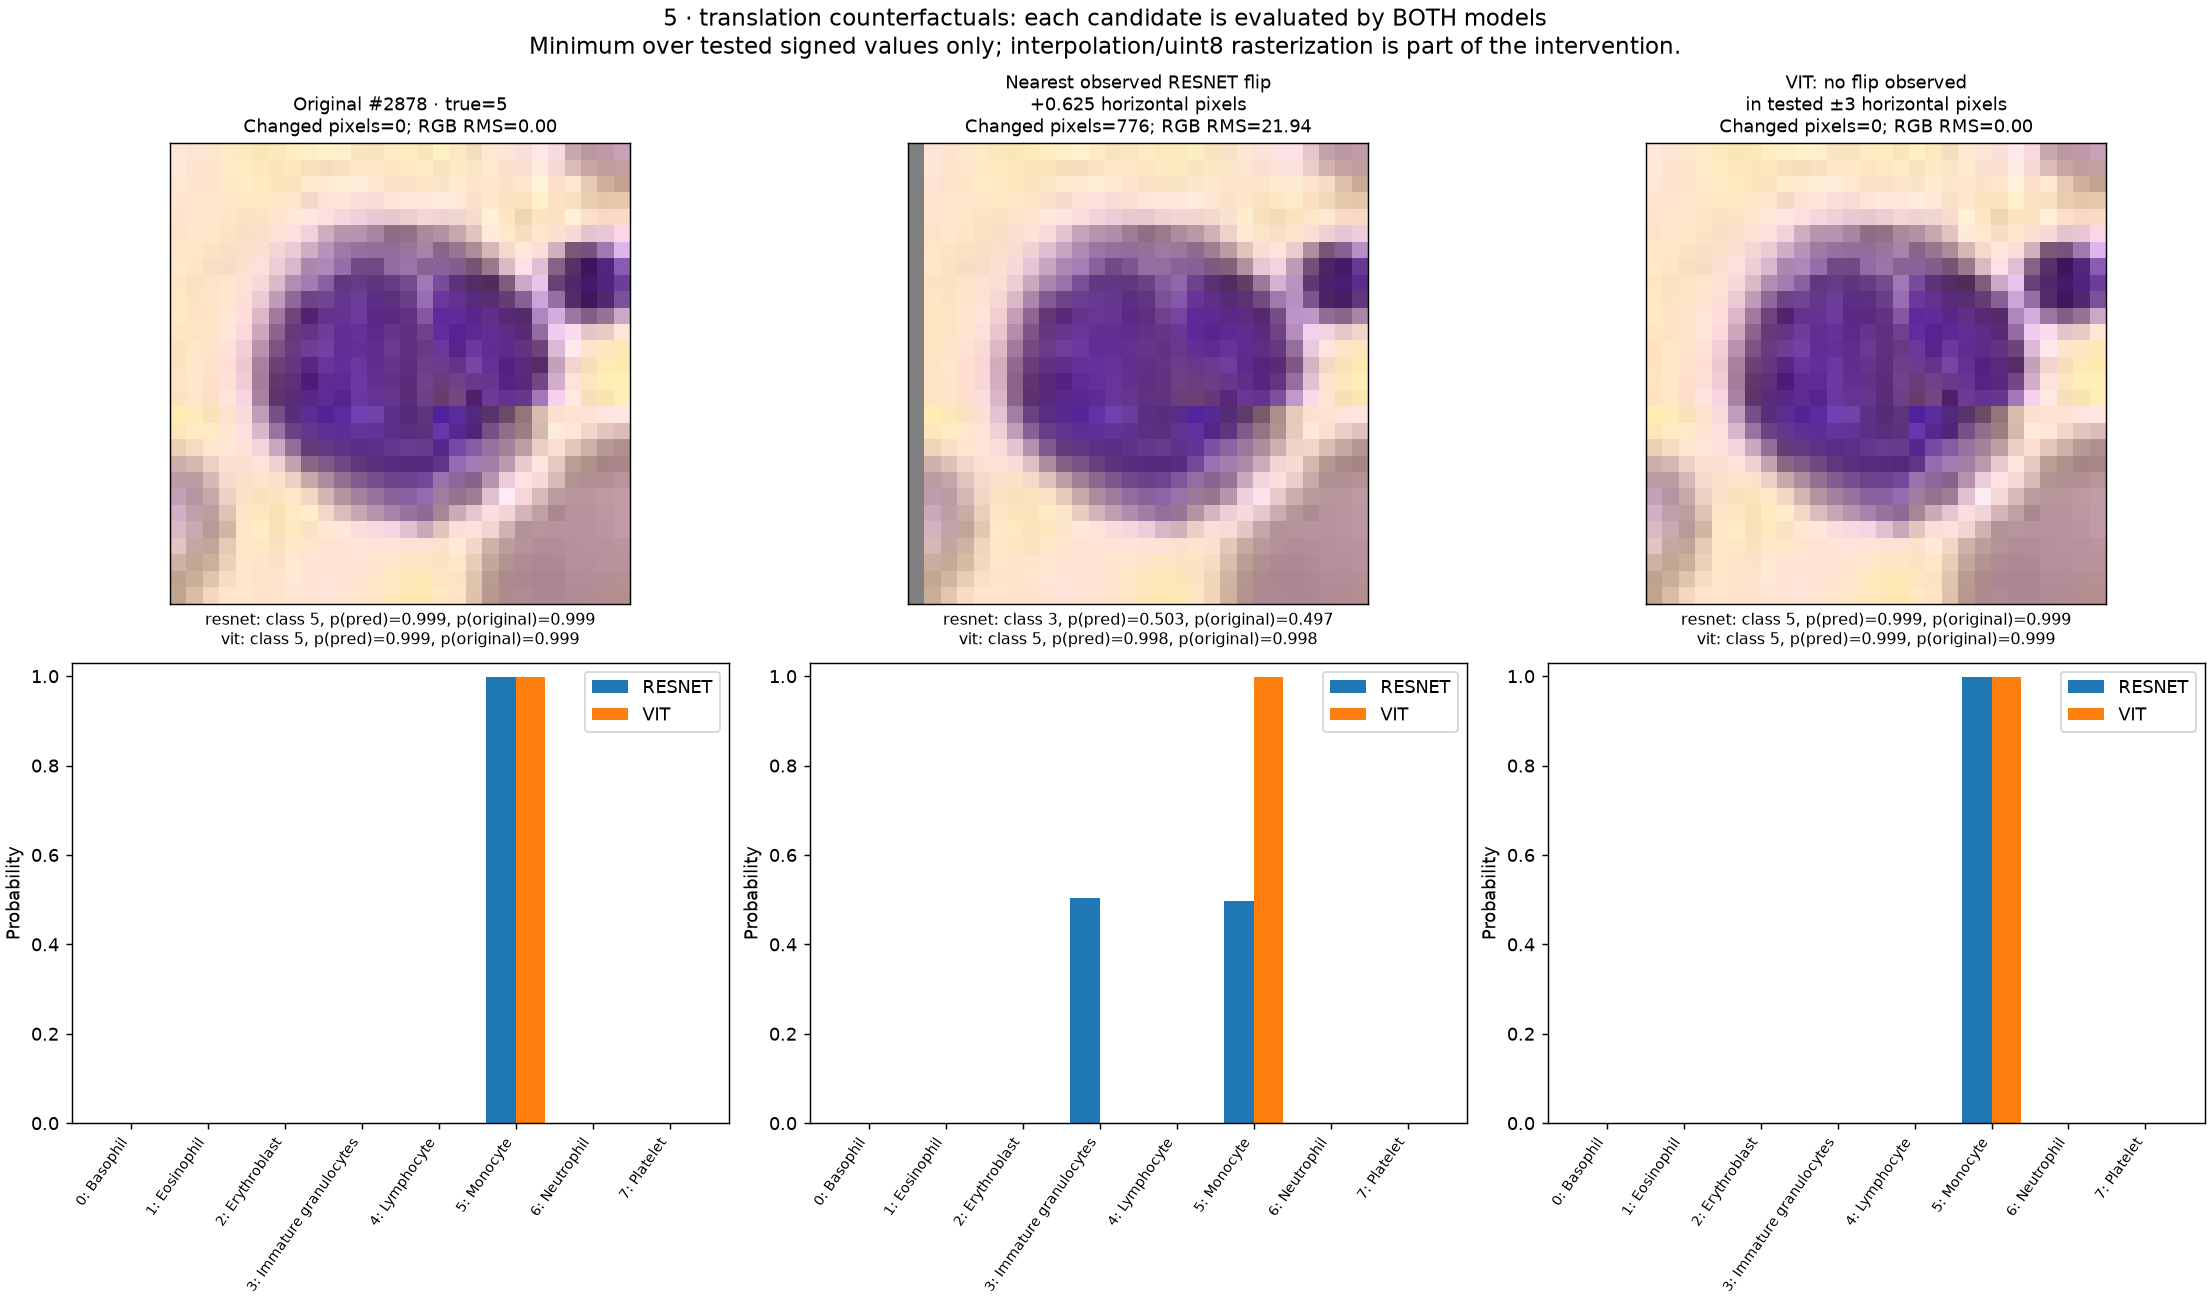

In [18]:
path_probabilities=np.stack(paths.probabilities.map(json.loads))
assert path_probabilities.shape==(len(paths),8)
np.testing.assert_allclose(path_probabilities.sum(1),1,atol=1e-5)
assert SAMPLE_ID in manifest_5["sample_indices"], "Set SAMPLE_ID to an existing E5 image"
fig,axes=plt.subplots(2,2,figsize=(16,9),layout="constrained")
for row,axis in enumerate(("rotation","translation")):
    for col,f in enumerate(MODELS):
        q=paths[(paths.sample_index==SAMPLE_ID)&(paths.axis==axis)&(paths.model==f)].sort_values("value")
        prob=path_probabilities[q.index]
        base=int(q.baseline_prediction.iloc[0])
        ax=axes[row,col]
        for cls in range(8):
            ax.plot(q.value,prob[:,cls],lw=2 if cls==base else .8,label=f"{cls}: {SHORT[cls]}")
        ax.axvline(0,color="black",linestyle=":",lw=.8)
        ax.set(title=f"#{SAMPLE_ID} {f.upper()} {axis}; baseline={base}",xlabel=config_5["axes"][axis]["unit_name"],
               ylabel="Probability",ylim=(-.02,1.02))
        ax.legend(fontsize=6,ncol=2)
fig.suptitle("All class probabilities; lines connect tested points only")
plt.show()
for axis in ("rotation","translation"):
    saved_figure(f"results/counterfactual/figures/counterfactuals/{axis}_sample_{SAMPLE_ID:05d}.png",width=1300)

### Switch, return, switch: inspect values, not just a smooth line

The following is a post-search illustration on #2878, not a new selection for a benchmark. Small reentrant intervals may reflect bilinear interpolation, gray fill, low source resolution and uint8 rounding. They survived the endpoint repeat audit, but should not be interpreted as biological changes.

,model,value,true_class,prediction,retained_baseline_probability,p_true_class,actually_changed_pixels,rms_rgb_change_whole_image
5917,resnet,0.000,Monocyte,5,0.9985,0.9985,0,0.0000
6212,vit,0.000,Monocyte,5,0.9986,0.9986,0,0.0000
5937,resnet,5.000,Monocyte,5,0.5104,0.5104,772,20.9112
6232,vit,5.000,Monocyte,5,0.9982,0.9982,772,20.9112
5938,resnet,5.025,Monocyte,3,0.4767,0.4767,772,20.9530
6233,vit,5.025,Monocyte,5,0.9982,0.9982,772,20.9530
5939,resnet,5.050,Monocyte,5,0.5006,0.5006,772,20.9932
6234,vit,5.050,Monocyte,5,0.9982,0.9982,772,20.9932
5940,resnet,5.075,Monocyte,3,0.4964,0.4964,773,21.0406
6235,vit,5.075,Monocyte,5,0.9982,0.9982,773,21.0406


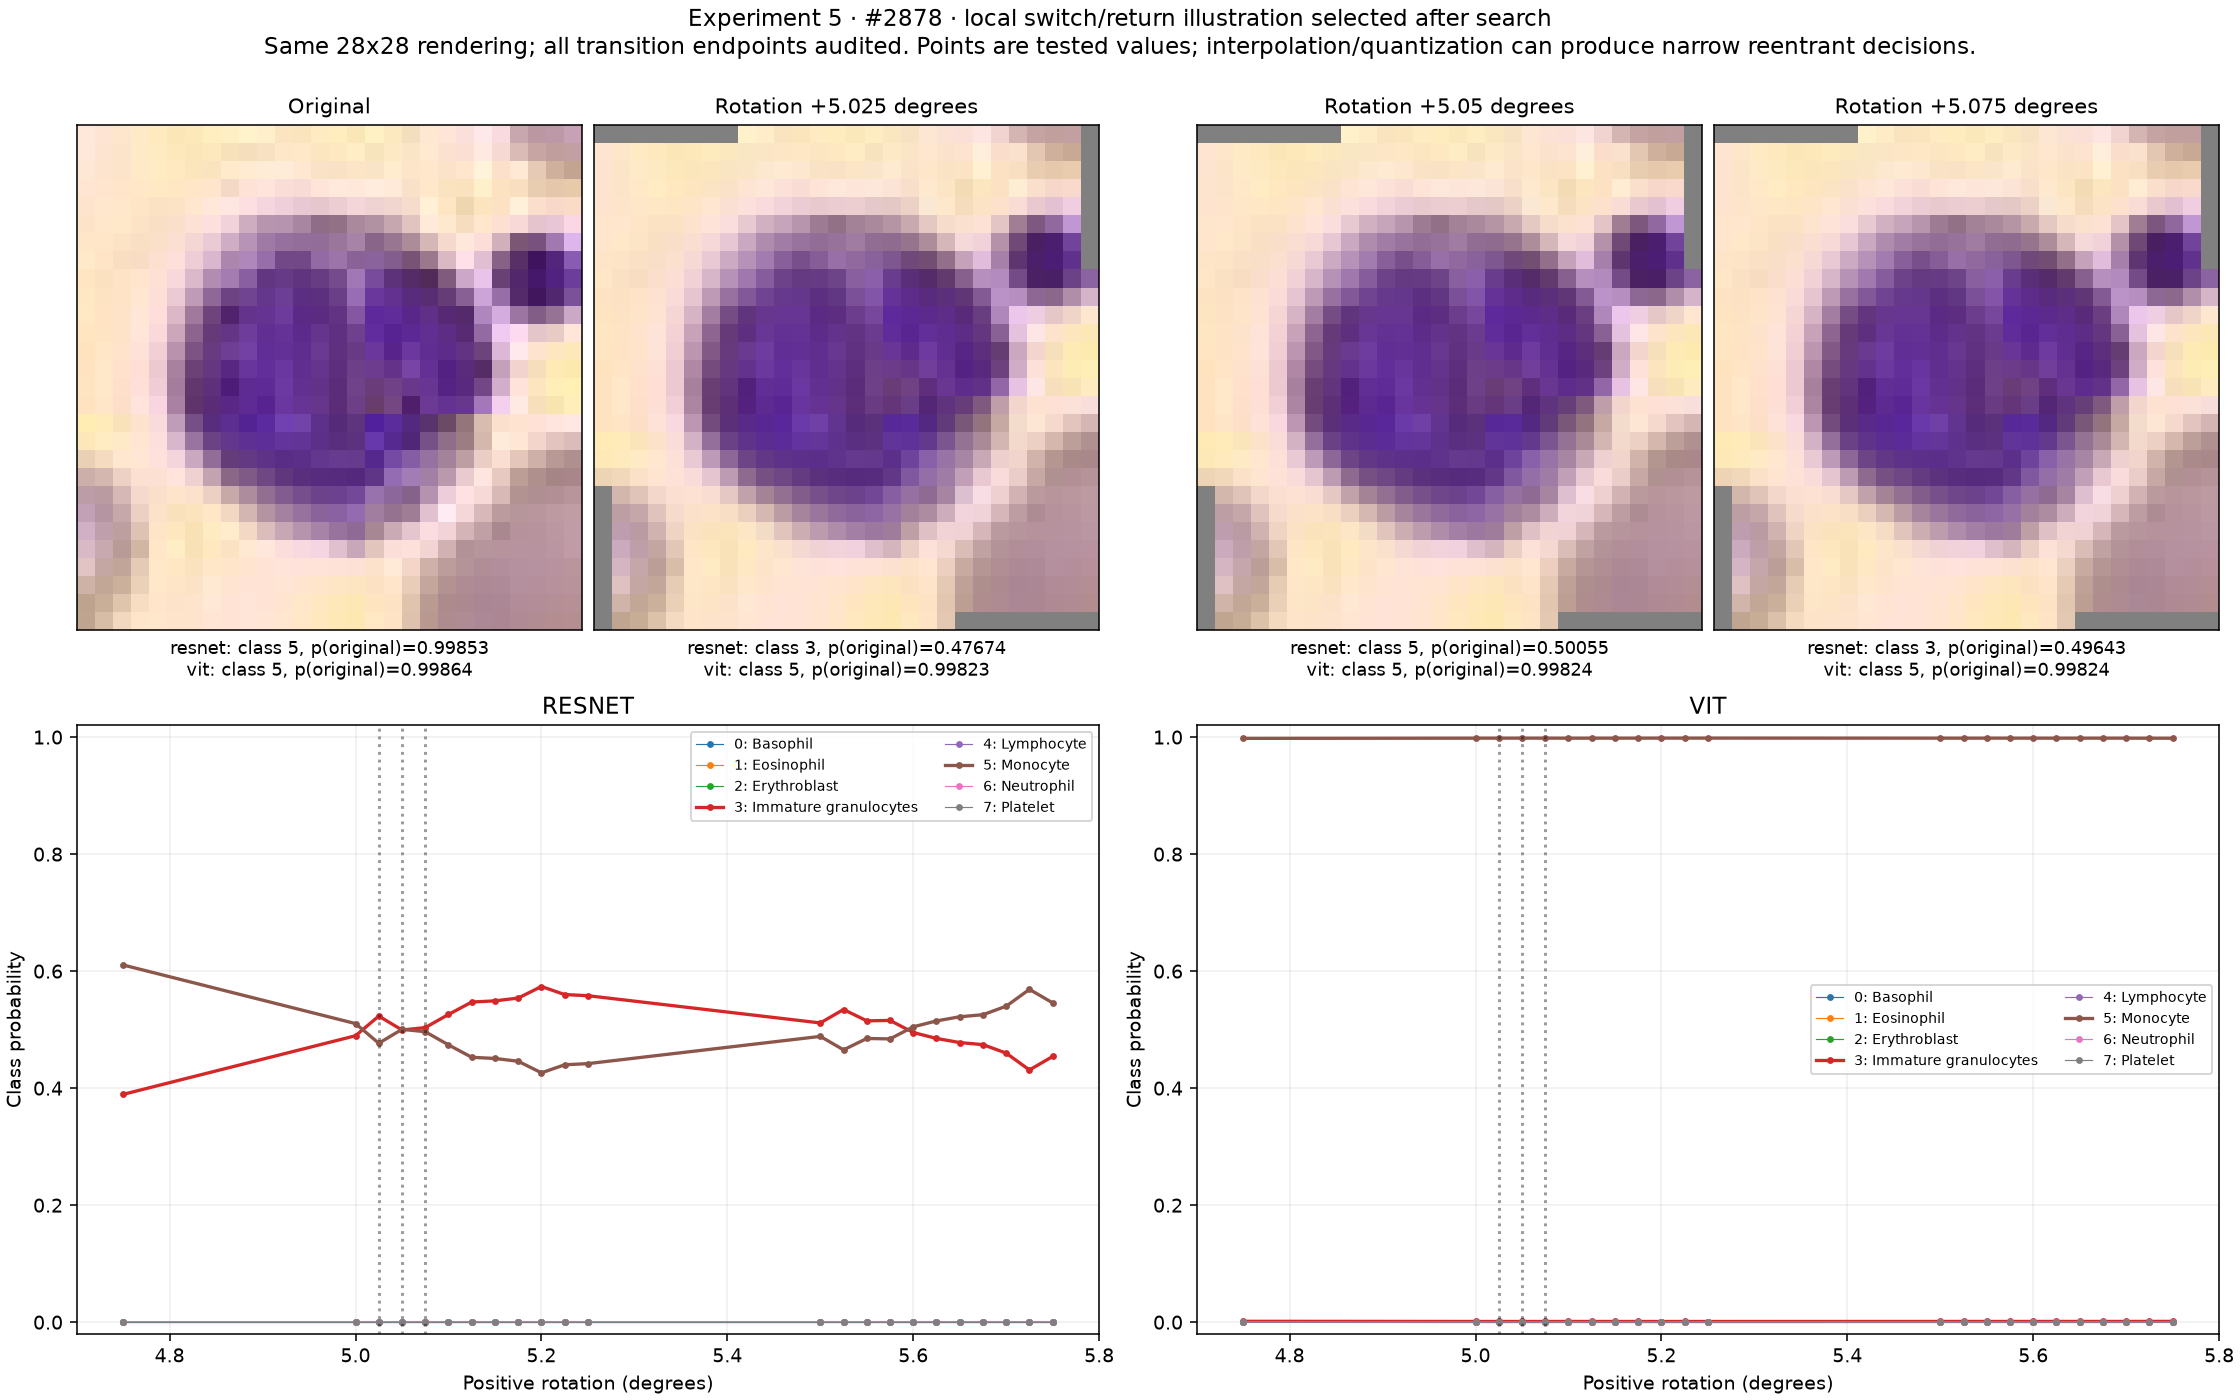

,endpoints,repeats,max_abs_error_from_saved,max_repeat_probability_range,min_top2_probability_margin,argmax_mismatches,warnings
resnet,255,3,0.0,0.0,0.0001,0,[]
vit,255,3,0.0,0.0,0.0002,0,[]


Endpoint audit evaluates only observed endpoints, not unsampled points or arbitrary devices.
Counterexample to a blanket model ranking: #809 ViT switches at -0.1px, ResNet at -0.85px;
ResNet is initially wrong there, and its later switch corrects its prediction.


In [19]:
trace=paths[(paths.sample_index==2878)&(paths.axis=="rotation")&paths.tick.isin([0,200,201,202,203])].copy()
trace["p_true_class"]=trace.true_class_probability
trace["true_class"]=trace.true_label.map(dict(enumerate(SHORT)))
display(trace[["model","value","true_class","prediction","retained_baseline_probability","p_true_class",
               "actually_changed_pixels","rms_rgb_change_whole_image"]].sort_values(["value","model"]))
saved_figure("results/counterfactual/figures/boundary_zoom_sample_02878.png",width=1400)
endpoint_audit=read_json("results/counterfactual/validation/transition_endpoint_audit.json")
display(pd.DataFrame(endpoint_audit["models"]).T)
print("Endpoint audit evaluates only observed endpoints, not unsampled points or arbitrary devices.")
print("Counterexample to a blanket model ranking: #809 ViT switches at -0.1px, ResNet at -0.85px;")
print("ResNet is initially wrong there, and its later switch corrects its prediction.")

## 9. Cross-experiment checks and questions

Verify overlapping, identically defined brightness interventions rather than assuming exports agree. Then compare image-level sensitivities, keeping shared targets and selection explicit. Correlations here are **descriptive**, not independent tests or evidence of mechanism.

In [20]:
old_brightness=stability_images[(stability_images.transformation=="brightness")&stability_images.level.isin([.9,1.1])].copy()
old_brightness["transformation"]=old_brightness.level.map(lambda level:f"brightness_{level:g}")
new_brightness=color[color.transformation.isin(["brightness_0.9","brightness_1.1"])]
consistency=old_brightness.merge(new_brightness,on=["sample_index","model","transformation"],suffixes=("_e2","_e4"),validate="one_to_one")
consistency["probability_difference"]=(consistency.retained_baseline_probability_e2-consistency.retained_baseline_probability_e4).abs()
np.testing.assert_allclose(consistency.retained_baseline_probability_e2,consistency.retained_baseline_probability_e4,atol=5e-4,rtol=1e-4)
assert (consistency.label_flipped_e2==consistency.label_flipped_e4).all()
print("Identical brightness controls:",len(consistency),"matched image/model/level pairs; all flip decisions agree.")
display(consistency.groupby("model").probability_difference.agg(["max","mean","count"]))
geometry_checks=read_table("results/counterfactual/validation/prior_geometry_equivalence.csv")
display(geometry_checks.groupby(["model","axis"]).max_probability_error.agg(["max","count"]))
print("These compare executions of the same interventions, not independent experimental evidence.")

Identical brightness controls: 36 matched image/model/level pairs; all flip decisions agree.


,max,mean,count
model,,,
resnet,2.5034e-06,3.5288e-07,18
vit,2.6822e-06,4.1144e-07,18


max  count
model  axis                          
resnet rotation     1.5497e-06     18
       translation  2.6226e-06     18
vit    rotation     1.4603e-06     18
       translation  3.5465e-06     18

These compare executions of the same interventions, not independent experimental evidence.


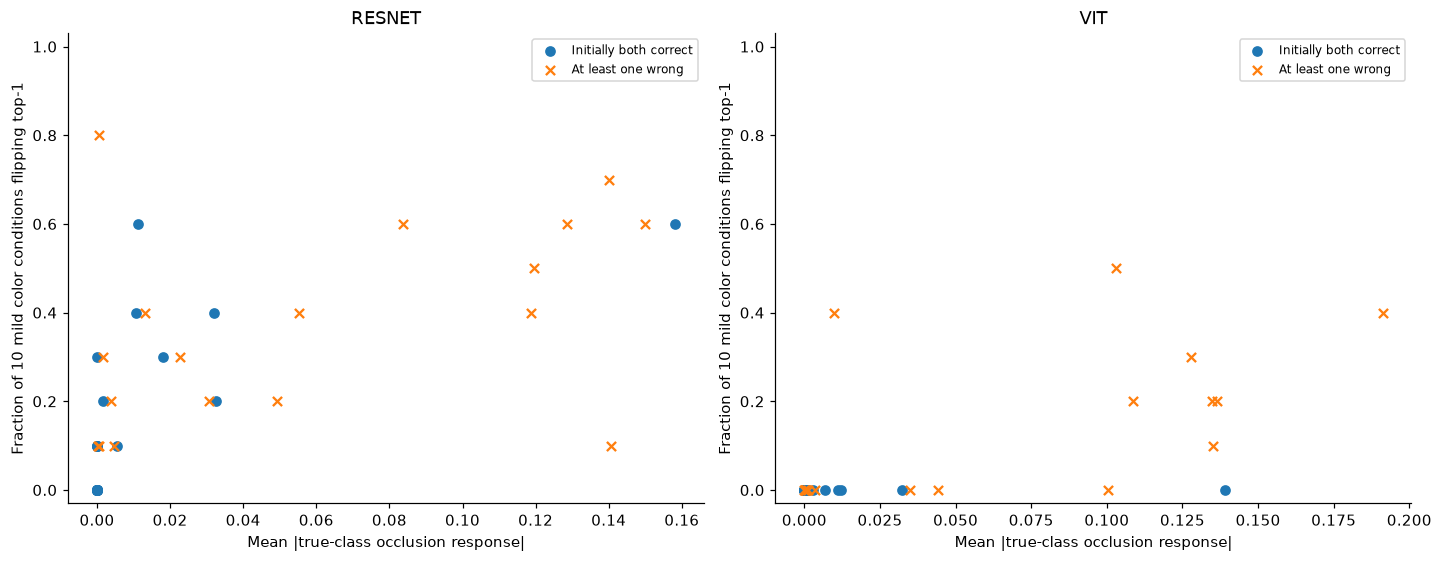

,model,subset,n_images,descriptive Spearman rho
0,resnet,All 48,48,0.8431
1,resnet,Initially both correct,30,0.8004
2,vit,All 48,48,0.5857
3,vit,Initially both correct,30,NaN


NaN correlation means no variation, not zero association. No p-values or mechanistic claims implied.


In [21]:
mild_per_image=mild.groupby(["sample_index","model"],as_index=False).agg(color_flip_fraction=("label_flipped","mean"))
joined=mild_per_image.merge(occlusion_true[["sample_index","model","mean_absolute_importance"]],
                            on=["sample_index","model"],validate="one_to_one")
joined["both_correct"]=joined.sample_index.map((all_test.group=="both_correct").to_dict())
correlation_rows=[]
fig,axes=plt.subplots(1,2,figsize=(13,5),layout="constrained")
for ax,f in zip(axes,MODELS):
    q=joined[joined.model==f]
    for state,marker in ((True,"o"),(False,"x")):
        r=q[q.both_correct==state]
        ax.scatter(r.mean_absolute_importance,r.color_flip_fraction,marker=marker,
                   label="Initially both correct" if state else "At least one wrong")
    ax.set(title=f.upper(),xlabel="Mean |true-class occlusion response|",ylabel="Fraction of 10 mild color conditions flipping top-1",ylim=(-.03,1.03))
    ax.legend(fontsize=8)
    for subset,r in (("All 48",q),("Initially both correct",q[q.both_correct])):
        rho=(float(spearmanr(r.mean_absolute_importance,r.color_flip_fraction).statistic)
             if r.mean_absolute_importance.nunique()>1 and r.color_flip_fraction.nunique()>1 else np.nan)
        correlation_rows.append({"model":f,"subset":subset,"n_images":len(r),"descriptive Spearman rho":rho})
plt.show()
display(pd.DataFrame(correlation_rows))
print("NaN correlation means no variation, not zero association. No p-values or mechanistic claims implied.")

In [22]:
profiles=all_test.loc[manifest_5["sample_indices"],["true_class","group","resnet_class","vit_class"]].copy()
for f in MODELS:
    profiles[f+" mild color flip fraction"]=mild_per_image[mild_per_image.model==f].set_index("sample_index").color_flip_fraction
    profiles[f+" mean true-class occlusion response"]=response[f]
    for axis in ("rotation","translation"):
        profiles[f+" nearest |"+axis+"|"]=nearest[(nearest.model==f)&(nearest.axis==axis)].set_index("sample_index").absolute_value
display(profiles)
print("NaN minima remain censored. Do not fill with infinity or mix degrees, pixels and probabilities into a ranking.")

,true_class,group,resnet_class,vit_class,resnet mild color flip fraction,resnet mean true-class occlusion response,resnet nearest |rotation|,resnet nearest |translation|,vit mild color flip fraction,vit mean true-class occlusion response,vit nearest |rotation|,vit nearest |translation|
sample_index,,,,,,,,,,,,
65,basophil,only_vit_correct,"immature granulocytes(myelocytes, metamyelocyt...",basophil,0.2,3.8439e-03,0.425,0.1000,0.0,1.0201e-04,26.450,NaN
105,"immature granulocytes(myelocytes, metamyelocyt...",only_vit_correct,monocyte,"immature granulocytes(myelocytes, metamyelocyt...",0.5,1.1951e-01,5.250,0.5125,0.0,3.3749e-03,9.100,NaN
194,neutrophil,both_correct,neutrophil,neutrophil,0.2,1.7741e-03,12.900,1.5000,0.0,2.3227e-05,NaN,NaN
432,monocyte,both_incorrect,"immature granulocytes(myelocytes, metamyelocyt...","immature granulocytes(myelocytes, metamyelocyt...",0.2,3.0541e-02,1.075,0.1625,0.0,1.0530e-03,8.125,0.525
809,neutrophil,only_vit_correct,"immature granulocytes(myelocytes, metamyelocyt...",neutrophil,0.1,1.4050e-01,NaN,0.8500,0.3,1.2773e-01,1.600,0.100
906,eosinophil,both_incorrect,"immature granulocytes(myelocytes, metamyelocyt...","immature granulocytes(myelocytes, metamyelocyt...",0.3,2.2606e-02,1.125,0.1875,0.2,1.0861e-01,3.150,0.775
2494,monocyte,both_correct,monocyte,monocyte,0.1,2.9132e-07,11.725,2.0000,0.0,1.3362e-05,NaN,NaN
2878,monocyte,both_correct,monocyte,monocyte,0.6,1.1201e-02,5.025,0.6250,0.0,2.7793e-03,NaN,NaN


NaN minima remain censored. Do not fill with infinity or mix degrees, pixels and probabilities into a ranking.


## 10. Working interpretation and useful next questions

- **Performance and sensitivity differ.** Inspect paired errors and wrong-to-correct switches, not only stable/unstable labels.
- **Selection matters.** The explanation set has far more disagreements than the full test set. The same initially-correct subset is the better available color-sensitivity control.
- **Confidence can mislead.** Both checkpoints make very confident errors; probability changes are not calibrated biological evidence.
- **Spatial/color responses are not anatomy.** Low target scores constrain positive occlusion responses. Approximate masks and matched dispersed-pixel controls still have context/semantic limitations.
- **Means hide heterogeneity.** Regional averages can be driven by a few vulnerable images; inspect medians, individual responses and initial correctness.
- **Counterfactual paths are non-monotonic and rasterization-specific.** Fine switches are numerically repeatable, not continuous/global minima. Adaptive sampling density is not a probability measure.
- **No blanket architecture ranking.** #809 is a useful counterexample; checkpoint provenance and preprocessing are not controlled architectural factors.

Explore: Which initially-correct images fail under color but not geometry? Are confident errors shared? Do map differences survive matching the target and initial correctness? Do regional effects persist for both signs/magnitudes? Does a tiny nearest switch mark a broad unstable interval or a narrow reentrant one?

No additional experiments or report files are generated by this notebook.

In [23]:
both_correct_mild=color_controlled[color_controlled["subset"]=="Initially both correct"].set_index("model")
print("Controlled color result:")
for f in MODELS:
    r=both_correct_mild.loc[f]
    print(f.upper(),int(r.flips),"flips /",int(r["image-condition pairs"]),"pairs on",int(r.unique_images),"shared initially-correct images")
print("Full-test confidently wrong predictions (confidence >= .99):")
print(pd.DataFrame(calibration_rows).set_index("model")["wrong with confidence >= 0.99"].to_dict())
print("Counterfactual paths:",len(transitions),"transitions,",int(transitions.returns_to_baseline.sum()),"returns.")

Controlled color result:
RESNET 35 flips / 300 pairs on 30 shared initially-correct images
VIT 0 flips / 300 pairs on 30 shared initially-correct images
Full-test confidently wrong predictions (confidence >= .99):
{'resnet': 47, 'vit': 20}
Counterfactual paths: 137 transitions, 57 returns.


## 11. Complete saved-visualization atlas

Every existing PNG in `results/` is indexed below: pilots, correctness/distribution galleries, all E2 curves/fingerprints/transition grids, all E3 maps, all E4 matrices/masks/region pages, and all E5 paths/counterfactuals. Links resolve relative to this notebook when opened from the repository in Jupyter. Representative figures are embedded above; links avoid duplicating every large figure.

Original exploration: [predictions.ipynb](predictions.ipynb). Prediction-generation source, **not executed here**: [get_predictions.ipynb](../skript/get_predictions.ipynb).

In [24]:
from urllib.parse import quote
from html import escape
figures=sorted(RESULTS.rglob("*.png"))
rows=[]
for file in figures:
    rel=file.relative_to(ROOT)
    rows.append({"experiment":file.relative_to(RESULTS).parts[0],"family":"/".join(file.relative_to(RESULTS).parts[1:-1]),
                 "figure":file.name,"href":quote("../"+rel.as_posix())})
atlas=pd.DataFrame(rows)
display(atlas.groupby(["experiment","family"]).size().rename("saved figures").to_frame())
for experiment,group in atlas.groupby("experiment",sort=False):
    html="<details><summary><b>"+escape(experiment)+"</b>: "+str(len(group))+" figures</summary><ul>"
    html+="".join('<li><a href="'+r.href+'">'+escape(r.family+"/"+r.figure)+"</a></li>" for r in group.itertuples())
    display(HTML(html+"</ul></details>"))
print("All newly computed displays are inside this notebook; no external figures/tables/reports were written.")

saved figures
experiment       family                                  
analysis         test/figures                           7
                 train/figures                          5
                 val/figures                            7
color_background figures                                9
                 pilot                                  3
counterfactual   figures                                2
                 figures/counterfactuals               16
                 figures/probability_paths             16
                 pilot                                  1
occlusion        figures/sensitivity_maps              48
                 pilot                                  1
stability        figures                                1
                 figures/curves                         8
                 figures/transition_grids              16
                 pilot                                  8

All newly computed displays are inside this notebook; no external figures/tables/reports were written.


## 12. General interpretation: how the two models behave

### Overall picture

For these checkpoints, **ViT is generally more accurate and less sensitive to the tested color, brightness and geometric changes than ResNet**. This appears both in the larger stability experiment and in the selected explanation images. However, ViT is not invariant, and the difference depends on the intervention and image. We found different sensitivity patterns, not universal architectural superiority.

### ResNet: good normal-image performance, but sensitive to appearance changes

ResNet achieves **95.79% full-test accuracy**, but often changes its prediction under brightness and channel modifications. A confident original decision can change after a small adjustment: reducing the red channel by 5% on **#194** changes its initially correct neutrophil prediction to monocyte, while ViT stays correct.

This is not explained only by ResNet having more original errors. On the **same 30 images both models initially classify correctly**, ResNet changes class in **35/300 mild image/condition pairs**, compared with **0/300 for ViT**. These are repeated conditions on 30 images, not 300 independent observations, but they control for initial correctness.

Grayscale changes ResNet's class on **43/48 explanation images**, supporting substantial color dependence for this checkpoint on this set. It does not prove reliance on irrelevant color shortcuts: staining can carry useful diagnostic information, and grayscale removes it.

ResNet is not uniformly fragile, and some switches improve its prediction. On **#809**, its -0.85-pixel horizontal-translation switch corrects an original error. A changed class is therefore not automatically deterioration.

### ViT: generally steadier, but with specific vulnerabilities

ViT reaches **96.99% full-test accuracy**, about **1.20 percentage points higher**. The paired comparison finds 94 images correct only for ViT versus 53 correct only for ResNet; **50 test images are wrong for both**.

ViT is generally steadier under the tested brightness, channel, translation and rotation changes. But **blur affects the models more similarly**: averaging the configured blur levels equally gives flip fractions of approximately **24.6% for ResNet and 21.5% for ViT**. These are severity-grid-specific values, not general robustness rates. Grayscale changes ViT's class on **22/48 images**, so tolerance to mild color changes is not independence from color.

There are clear exceptions to a simple ranking. On **#809**, ViT changes under a smaller leftward translation (-0.1 pixels) than ResNet (-0.85 pixels), and also changes under rotation while no ResNet rotation switch is observed within the tested range. Their original decisions differ there, so they are not starting from equivalent predictions.

### Spatial findings: central content matters, but averages hide vulnerable cases

Occlusion maps locate sensitivity to artificial patch changes, not nuclei, cytoplasm, attention or biological reasoning. Compare the **same target class** across models and consider initial correctness. A low original target score can constrain a positive probability drop.

With equal-area, equal-intensity regional controls, **both models have larger average central-region responses than peripheral responses**. This supports greater sensitivity to the approximate central content under these controls, not exclusive use of either cell or background. Peripheral regions can contain other cells.

The average is not typical of every image. For ViT's stronger matched central controls, **three of 16 images contribute about 78% of the total absolute true-class probability response**; its median response is much smaller than its mean. Masks are approximate assistant-reviewed regions, not expert segmentation. Matched controls change dispersed pixels, not entire contiguous structures.

Among the 30 initially-both-correct images, ResNet's mild-color flip fraction and true-class occlusion sensitivity are strongly associated descriptively (**Spearman rho about 0.80**). Some of the same images are vulnerable under different intervention families. This small selected-set association does not establish a shared cause or control for baseline confidence and image features.

### Decision boundaries: a switch is not a one-way threshold

On **#2878**, ResNet leaves monocyte at **+5.025 degrees**, returns at **+5.05 degrees**, and leaves again at **+5.075 degrees**. ViT retains monocyte at those points. Endpoint repeats reproduce these decisions, but bilinear interpolation, gray fill and uint8 rounding are part of the intervention.

The **137 observed transitions and 57 returns** describe non-monotonic paths, not independent failures. The nearest observed switch depends on transformation family, sign, range, grid and rasterization. It is not a globally smallest perturbation or continuous robustness certificate; narrower unobserved class islands may remain.

### What we can reasonably conclude

**This ViT checkpoint is generally more tolerant than this ResNet checkpoint to the tested appearance and geometric changes, while both have image-specific weaknesses and sensitivity to central content.** Neither model's confidence guarantees reliability: **47 ResNet and 20 ViT full-test errors have confidence at least 99%**.

These are descriptive checkpoint-specific findings. The explanation set is disagreement-enriched, and training provenance and preprocessing differ: ResNet receives 28x28 inputs, while ViT receives resized 224x224 versions of the same low-resolution source. We cannot attribute the differences solely to convolution versus attention, infer local-texture versus global-shape reasoning, or claim clinical validity or guaranteed label preservation. The useful outcome is a concrete view of **where each checkpoint is stable, where it is sensitive, and which cases merit closer inspection**.